<a href="https://colab.research.google.com/github/gcastellanoscsmmc-prog/Visible-Spectrophotometer-Data-and-Code/blob/main/CodeSpectra_ENGLISH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DIY Camera-Based Spectrophotometer: Spectral Analysis and Comparison with Commercial UV–Vis

**Purpose.** This notebook provides a reproducible workflow for processing spectral images acquired with a low-cost, homemade spectrophotometer. It includes wavelength calibration, dark correction, apparent absorbance calculations, basic descriptive statistics, spectral quality assessment, and exploratory comparison with a commercial UV–Vis spectrophotometer (VWR UV-3100PC).

**Instructions.** Open the notebook in Google Colab and select **Runtime → Run all**. When prompted, upload the ZIP file containing the required original spectral photographs and commercial CSV files. The notebook processes the data, generates figures, and exports the selected results as a downloadable ZIP archive.

**Important limitations.** The DIY wavelength calibration is experimentally between **365-650 nm**; the commercial instrument covers **300–700 nm**. DIY absorbance values are reported as *apparent absorbance* because JPEG pixel intensities are not calibrated photometric measurements. Negative values, invalid intensity ratios, and potentially saturated regions are documented rather than artificially corrected.

**Intended use.** This notebook supports educational experimentation, spectral interpretation, and investigation of instrumental limitations. It does not constitute a validated quantitative analytical method.

In [1]:
# ============================================================
# 1. LIBRARY INSTALLATION AND WORKING DIRECTORIES
# ============================================================

import sys, subprocess, importlib.util

# Install required packages if they are not available
for paquete in (
    "numpy", "pandas", "matplotlib",
    "scipy", "PIL", "nbformat", "openpyxl"
):
    if importlib.util.find_spec(paquete) is None:
        pip_nombre = "Pillow" if paquete == "PIL" else paquete
        subprocess.check_call([
            sys.executable, "-m", "pip",
            "install", "-q", pip_nombre
        ])

# Import required libraries
from pathlib import Path
from zipfile import ZipFile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.interpolate import interp1d
from scipy.stats import linregress
from scipy.signal import savgol_filter
from IPython.display import display

# Spectral wavelength ranges (DIY spectrophotometer)
PLOT_MIN, PLOT_MAX = 300, 700
CAL_MIN, CAL_MAX = 300, 700

BASE_DIR = Path('/content') if Path('/content').exists() else Path.cwd()
DATA_DIR = BASE_DIR / 'uvvis_photographs'
COMMERCIAL_DIR = BASE_DIR / 'commercial_data'
OUTPUT_DIR = BASE_DIR / 'uvvis_results'

DATA_DIR.mkdir(parents=True, exist_ok=True)
COMMERCIAL_DIR.mkdir(parents=True, exist_ok=True)

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Working directory:', BASE_DIR)
print('DIY photographs:', DATA_DIR)
print('Commercial data:', COMMERCIAL_DIR)
print('Results:', OUTPUT_DIR)

print('\nLibrary installation and directory setup completed successfully.')

Working directory: /content
DIY photographs: /content/uvvis_photographs
Commercial data: /content/commercial_data
Results: /content/uvvis_results

Library installation and directory setup completed successfully.


In [2]:
# ============================================================
# 2. DEFINE PLOT STYLE AND FIGURES
# ============================================================

from cycler import cycler

CB_PALETTE = {
    'black': '#000000',
    'orange': '#E69F00',
    'sky_blue': '#56B4E9',
    'bluish_green': '#009E73',
    'yellow': '#F0E442',
    'blue': '#0072B2',
    'vermillion': '#D55E00',
    'reddish_purple': '#CC79A7',
    'gray': '#7F7F7F'
}

ARTICLE_COLORS = [
    CB_PALETTE['blue'],
    CB_PALETTE['vermillion'],
    CB_PALETTE['bluish_green'],
    CB_PALETTE['reddish_purple'],
    CB_PALETTE['orange'],
    CB_PALETTE['sky_blue'],
    CB_PALETTE['gray'],
    CB_PALETTE['black']
]

ARTICLE_LINESTYLES = [
    '-',
    '--',
    '-.',
    ':',
    (0, (5, 1)),
    (0, (3, 1, 1, 1)),
    (0, (1, 1))
]

ARTICLE_MARKERS = [
    'o', 's', '^', 'D', 'v', 'P', 'X'
]

plt.rcParams.update({
    'figure.figsize': (10, 5),
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'legend.fontsize': 9,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'lines.linewidth': 2.0,
    'axes.prop_cycle': cycler(color=ARTICLE_COLORS)
})

SAMPLE_STYLE = {
    'Water': {'color': CB_PALETTE['blue'], 'linestyle': '-', 'linewidth': 2.2},
    'Yellow 5': {'color': CB_PALETTE['orange'], 'linestyle': '-', 'linewidth': 2.0},
    'Yellow 6': {'color': CB_PALETTE['vermillion'], 'linestyle': '--', 'linewidth': 2.0},
    'Blue 1': {'color': CB_PALETTE['bluish_green'], 'linestyle': '-.', 'linewidth': 2.0},
    'Algae chlorophyll': {'color': CB_PALETTE['reddish_purple'], 'linestyle': ':', 'linewidth': 2.2},
    'Chlorophyllin': {'color': CB_PALETTE['black'], 'linestyle': (0, (5, 1)), 'linewidth': 2.2}
}

COMPARISON_STYLE = {
    'Commercial': {'color': CB_PALETTE['black'], 'linestyle': '-', 'linewidth': 2.2},
    'DIY': {'color': CB_PALETTE['blue'], 'linestyle': '--', 'linewidth': 2.2}
}

def get_concentration_style(index):
    return {
        'color': ARTICLE_COLORS[index % len(ARTICLE_COLORS)],
        'linestyle': ARTICLE_LINESTYLES[index % len(ARTICLE_LINESTYLES)],
        'linewidth': 1.8
    }

def apply_article_axes(ax, xlabel='Wavelength (nm)', ylabel=None,
                       xlim=(PLOT_MIN, PLOT_MAX), ylim=None):
    ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    ax.set_xlim(*xlim)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(True, alpha=0.25)

def combine_legends(ax_left, ax_right, loc='best'):
    lines_left, labels_left = ax_left.get_legend_handles_labels()
    lines_right, labels_right = ax_right.get_legend_handles_labels()
    ax_left.legend(lines_left + lines_right, labels_left + labels_right, loc=loc)

def save_article_figure(filename):
    plt.savefig(OUTPUT_DIR / filename, dpi=300, bbox_inches='tight')

print('Color palette loaded successfully.')
print('Gray color:', CB_PALETTE['gray'])

Color palette loaded successfully.
Gray color: #7F7F7F


In [3]:
# =====================================================================================================================
# 3. EXPERIMENTAL DATA CONFIGURATION AND FILE UPLOAD (Make sure to have all files requested in one single file or zip)
# =====================================================================================================================

# Wavelength calibration reference images
LASERS = {
    'UV 365 nm': ('UV_365nm_final.jpg', 365),
    'Blue 405 nm': ('Blue_405nm_final.jpg', 405),
    'Green 532 nm': ('Green_532nm_final.jpg', 532),
    'Red 650 nm': ('Red_650nm_final.jpg', 650)
}

# DIY spectrophotometer sample images
DYES = {
    'Water': 'Barrido_agua_Camara_final.jpg',
    'Yellow 5': 'Barrido_Amarillo_5_Camara_final.jpg',
    'Yellow 6': 'Barrido_Amarillo_6_Camara_final.jpg',
    'Blue 1': 'Barrido_Azul_1_Camara_final.jpg',
    'Algae chlorophyll': 'Barrido_Clorofila_algas_Camara_final.jpg',
    'Chlorophyllin': 'Barrido_Clorofilina_Camara_final.jpg',
    'Hibiscus extract': 'Barrido_Extracto_Jamaica_Etanol_Camara_final.jpg'
}

# Chlorophyllin concentration series (ppm)
CONCENTRATIONS = list(range(3, 31, 3))

# Required DIY photographs
REQUIRED_FILES = (
    ['Dark_Camara_final.jpg']
    + [x[0] for x in LASERS.values()]
    + list(DYES.values())
)

# Five ethanol blank measurements
REQUIRED_FILES += [
    f'Blk_{i}_Camara_final.jpg'
    for i in range(1, 6)
]

# Thirty chlorophyllin measurements
REQUIRED_FILES += [
    f'{ppm}ppm_Camara_{rep:02d}_final.jpg'
    for ppm in CONCENTRATIONS
    for rep in range(1, 4)
]

def all_files_available():
    return all(
        (DATA_DIR / name).is_file()
        for name in REQUIRED_FILES
    )

# Extract supported experimental files
def extract_experimental_zip(zip_path):
    with ZipFile(zip_path) as z:
        for info in z.infolist():

            if info.is_dir():
                continue

            if '__MACOSX' in info.filename:
                continue

            name = Path(info.filename).name
            extension = Path(name).suffix.lower()

            if name in REQUIRED_FILES:
                destination = DATA_DIR / name

            elif extension in ('.csv', '.xlsx'):
                destination = COMMERCIAL_DIR / name

            else:
                continue

            with z.open(info) as source:
                with destination.open('wb') as output:
                    shutil.copyfileobj(source, output)

# Determine whether additional files are needed
commercial_csv = list(COMMERCIAL_DIR.glob('*.csv'))
commercial_excel = list(COMMERCIAL_DIR.glob('*.xlsx'))

need_upload = (
    not all_files_available()
    or not commercial_csv
    or not commercial_excel
)

if need_upload:

    print('Upload experimental data files.')
    print('Accepted formats: ZIP, CSV, XLSX and required JPG images.')
    print('DIY photographs can be provided in one ZIP archive.')
    print('Commercial CSV and XLSX files can be uploaded together.')

    if BASE_DIR.as_posix() == '/content':

        from google.colab import files

        uploaded_files = files.upload()

        zip_files = [
            Path(name)
            for name in uploaded_files
            if name.lower().endswith('.zip')
        ]

        # Extract ZIP archives
        for zip_path in zip_files:
            extract_experimental_zip(zip_path)

        # Copy individual uploaded files
        for name in uploaded_files:

            extension = Path(name).suffix.lower()

            if name in REQUIRED_FILES:
                shutil.copy2(name, DATA_DIR / name)

            elif extension in ('.csv', '.xlsx'):
                shutil.copy2(name, COMMERCIAL_DIR / Path(name).name)

    else:

        zip_files = list(BASE_DIR.glob('*.zip'))

        for zip_path in zip_files:
            with ZipFile(zip_path) as z:
                contains_photographs = any(
                    Path(info.filename).name in REQUIRED_FILES
                    for info in z.infolist()
                )

            if contains_photographs:
                extract_experimental_zip(zip_path)

        for path in BASE_DIR.iterdir():

            if not path.is_file():
                continue

            if path.name in REQUIRED_FILES:
                shutil.copy2(path, DATA_DIR / path.name)

            elif path.suffix.lower() in ('.csv', '.xlsx'):
                shutil.copy2(path, COMMERCIAL_DIR / path.name)

missing_files = [
    name for name in REQUIRED_FILES
    if not (DATA_DIR / name).is_file()
]

print('\n--- DATA IMPORT SUMMARY ---')
print(f'DIY photographs: {len(REQUIRED_FILES)-len(missing_files)}/{len(REQUIRED_FILES)}')

# List commercial experimental files
commercial_csv = sorted(COMMERCIAL_DIR.glob('*.csv'))
commercial_excel = sorted(COMMERCIAL_DIR.glob('*.xlsx'))

print(f'Commercial spectral CSV files: {len(commercial_csv)}')
print(f'Commercial Excel files: {len(commercial_excel)}')

for path in commercial_csv + commercial_excel:
    print(' -', path.name)

if missing_files:
    raise FileNotFoundError(
        'Missing DIY photographs:\n'
        + '\n'.join(missing_files)
    )

print('\nExperimental file configuration completed successfully.')

Upload experimental data files.
Accepted formats: ZIP, CSV, XLSX and required JPG images.
DIY photographs can be provided in one ZIP archive.
Commercial CSV and XLSX files can be uploaded together.


Saving Barrido Amarillo 5.csv to Barrido Amarillo 5.csv
Saving Barrido Amarillo 6.csv to Barrido Amarillo 6.csv
Saving Barrido Azul 1.csv to Barrido Azul 1.csv
Saving Barrido blanco agua.csv to Barrido blanco agua.csv
Saving Barrido clorofila algas.csv to Barrido clorofila algas.csv
Saving Barrido Clorofilina etanol.csv to Barrido Clorofilina etanol.csv
Saving Barrido Clorofilina.csv to Barrido Clorofilina.csv
Saving Curva Referencia.xlsx to Curva Referencia.xlsx
Saving DIY Spectrophotometer Code Images.zip to DIY Spectrophotometer Code Images.zip

--- DATA IMPORT SUMMARY ---
DIY photographs: 47/47
Commercial spectral CSV files: 7
Commercial Excel files: 1
 - Barrido Amarillo 5.csv
 - Barrido Amarillo 6.csv
 - Barrido Azul 1.csv
 - Barrido Clorofilina etanol.csv
 - Barrido Clorofilina.csv
 - Barrido blanco agua.csv
 - Barrido clorofila algas.csv
 - Curva Referencia.xlsx

Experimental file configuration completed successfully.


In [4]:
# ============================================================
# 4. IMAGE PROCESSING AND DARK CORRECTION
# ============================================================

# Load RGB images as floating-point arrays
def load_rgb(name):
    path = DATA_DIR / name

    if not path.is_file():
        raise FileNotFoundError(
            f'Image file not found: {path}'
        )

    with Image.open(path) as img:
        return np.asarray(
            img.convert('RGB'),
            dtype=np.float64
        )


# Convert RGB values into weighted luminance
def luminance(rgb):
    return (
        0.299 * rgb[..., 0]
        + 0.587 * rgb[..., 1]
        + 0.114 * rgb[..., 2]
    )


# Load the dark-reference image
dark = load_rgb('Dark_Camara_final.jpg')

print('Dark-reference image loaded.')
print('Image dimensions:', dark.shape[1], 'x', dark.shape[0])
print('Color channels:', dark.shape[2])


# Subtract the dark-reference image
def subtract_dark(name):
    image = load_rgb(name)

    if image.shape != dark.shape:
        raise ValueError(
            f'Incompatible image dimensions for {name}: '
            f'{image.shape} vs {dark.shape}'
        )

    # Preserve negative values for diagnostic purposes
    return image - dark


# Extract a spectral intensity profile
def spectrum_profile(rgb, channel='L'):

    if rgb.ndim != 3 or rgb.shape[2] != 3:
        raise ValueError(
            'Expected an RGB image with three color channels.'
        )

    if channel not in ('L', 'R', 'G', 'B'):
        raise ValueError(
            'Channel must be L, R, G, or B.'
        )

    # Average 11 central rows to reduce pixel-level noise
    row = rgb.shape[0] // 2

    start_row = max(0, row - 5)
    end_row = min(rgb.shape[0], row + 6)

    region = rgb[start_row:end_row, :, :]

    if channel == 'L':
        return luminance(region).mean(axis=0)

    return region[:, :, 'RGB'.index(channel)].mean(axis=0)


# Calculate transmittance and apparent absorbance
def calculate_absorbance(intensity, blank, wavelengths):

    intensity = np.asarray(intensity, dtype=float)
    blank = np.asarray(blank, dtype=float)
    wavelengths = np.asarray(wavelengths, dtype=float)

    if (
        intensity.ndim != 1
        or blank.ndim != 1
        or wavelengths.ndim != 1
    ):
        raise ValueError(
            'Spectral profiles must be one-dimensional arrays.'
        )

    if (
        len(intensity) != len(blank)
        or len(intensity) != len(wavelengths)
    ):
        raise ValueError(
            'Spectral profiles have different lengths.'
        )

    A = np.full(len(intensity), np.nan, dtype=float)
    T = np.full(len(intensity), np.nan, dtype=float)

    # Only calculate ratios for valid positive signals
    valid = (
        np.isfinite(intensity)
        & np.isfinite(blank)
        & (intensity > 0)
        & (blank > 0)
        & np.isfinite(wavelengths)
        & (wavelengths >= CAL_MIN)
        & (wavelengths <= CAL_MAX)
    )

    T[valid] = intensity[valid] / blank[valid]
    A[valid] = -np.log10(T[valid])

    return T, A


# Apply consistent formatting to spectral plots
def format_wavelength_axis(ax):
    ax.set_xlim(PLOT_MIN, PLOT_MAX)
    ax.set_xlabel('Wavelength (nm)')
    ax.grid(True, alpha=0.25)


print('\nImage-processing functions initialized successfully.')
print('Spectral extraction: average of 11 central image rows.')
print('Dark correction: enabled.')
print('Output: transmittance and apparent absorbance.')
print('Invalid intensity values: excluded from absorbance calculations.')

Dark-reference image loaded.
Image dimensions: 1140 x 96
Color channels: 3

Image-processing functions initialized successfully.
Spectral extraction: average of 11 central image rows.
Dark correction: enabled.
Output: transmittance and apparent absorbance.
Invalid intensity values: excluded from absorbance calculations.


--- WAVELENGTH CALIBRATION ---
UV 365 nm: pixel = 147, peak contrast = 37.44, maximum original RGB value = 191/255
Blue 405 nm: pixel = 237, peak contrast = 22.40, maximum original RGB value = 205/255
Green 532 nm: pixel = 495, peak contrast = 3.41, maximum original RGB value = 26/255
Red 650 nm: pixel = 993, peak contrast = 70.65, maximum original RGB value = 255/255


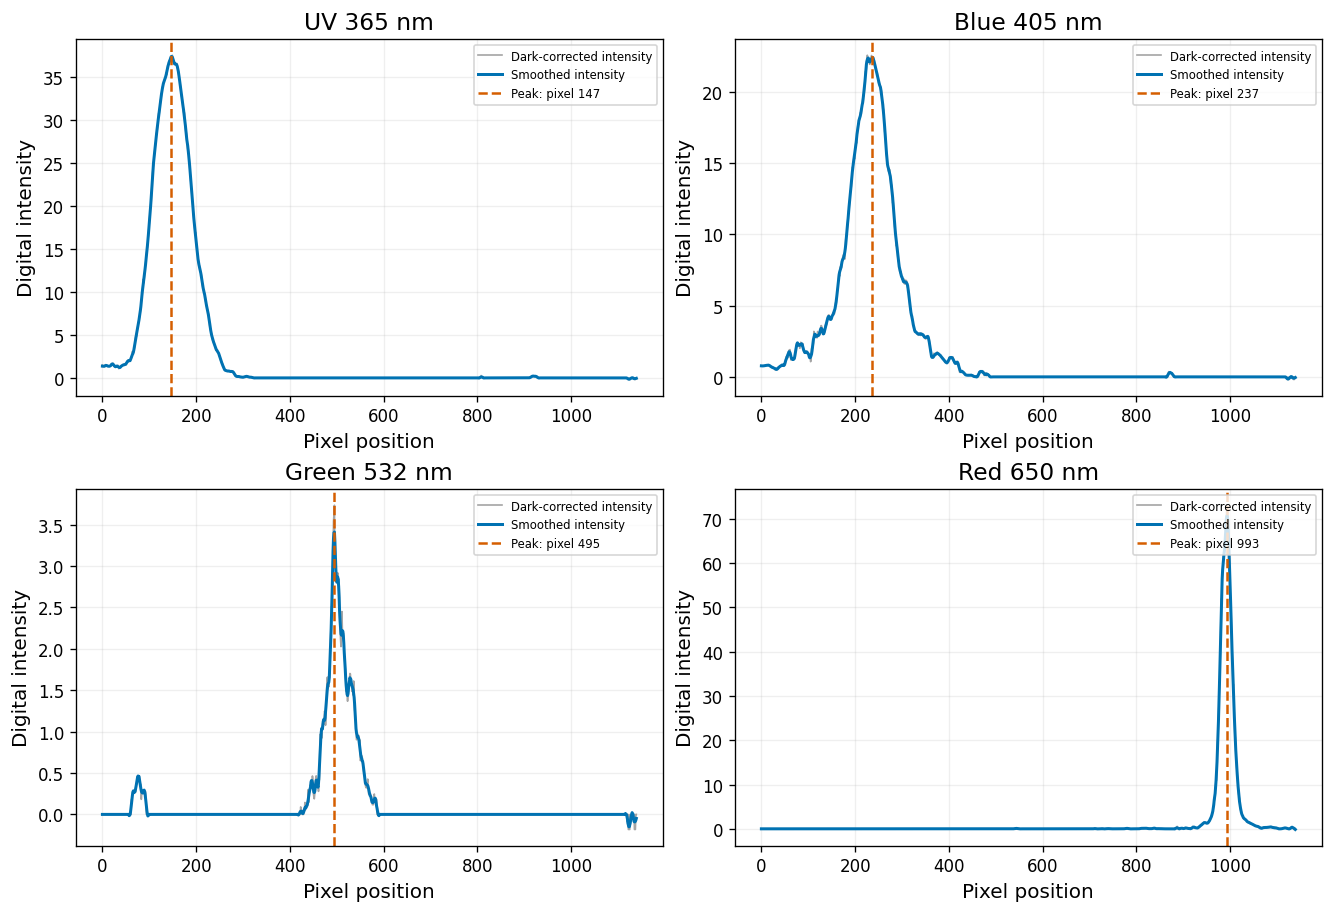

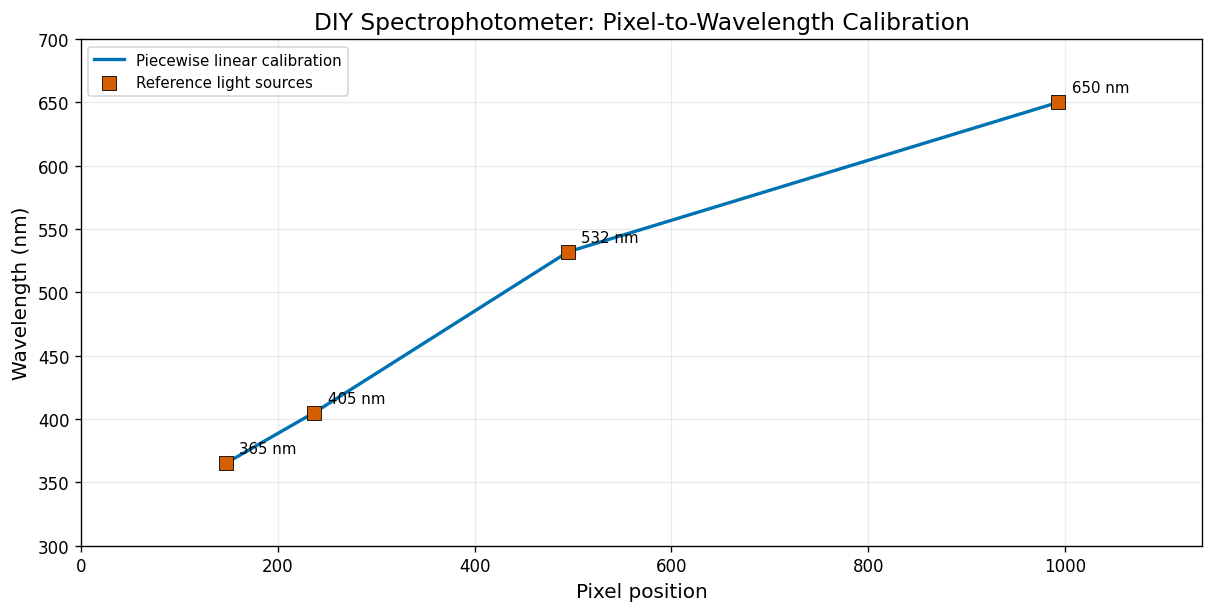


--- CALIBRATION SUMMARY ---
Configured plotting range: 300–700 nm
Experimentally anchored calibration range: 365–650 nm
Valid calibrated pixels: 847/1140
Target 403 nm: pixel 232, assigned wavelength 402.78 nm
Target 624 nm: pixel 883, assigned wavelength 623.94 nm

Extrapolation is disabled. Wavelengths outside the experimentally anchored interval are NaN.
Additional reference sources are required to validate the full 300–700 nm interval.

Wavelength calibration completed. Inspect all four assigned peaks before continuing.


In [5]:
# ============================================================
# 5. WAVELENGTH CALIBRATION AND VISUAL INSPECTION
# ============================================================

# Optional manual corrections for incorrectly detected peaks.
# Leave empty unless visual inspection identifies an error.
# Example: {'Green 532 nm': 520}
LASER_PEAK_OVERRIDES = {}

calibration_pixels = []
calibration_wavelengths = []
laser_profiles = {}

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 7.5),
    constrained_layout=True
)

axes = axes.ravel()

print('--- WAVELENGTH CALIBRATION ---')

for ax, (label, (filename, nm)) in zip(
    axes, LASERS.items()
):

    # Load the calibration image
    img = load_rgb(filename)

    # Verify complete image compatibility
    if img.shape != dark.shape:
        raise ValueError(
            f'Incompatible dimensions for {filename}: '
            f'{img.shape} vs {dark.shape}'
        )

    # Apply dark-reference correction
    corrected_image = img - dark

    # Extract the central-row averaged luminance profile
    intensity = spectrum_profile(corrected_image)

    # Apply mild smoothing for peak detection only
    smoothed_intensity = savgol_filter(
        intensity,
        window_length=11,
        polyorder=2
    )

    # Detect the strongest spectral peak
    max_px = int(np.argmax(smoothed_intensity))

    # Allow manually verified peak corrections
    if label in LASER_PEAK_OVERRIDES:
        max_px = int(LASER_PEAK_OVERRIDES[label])

    if not (0 <= max_px < len(intensity)):
        raise ValueError(
            f'Invalid peak pixel for {label}: {max_px}'
        )

    # Store calibration values
    calibration_pixels.append(max_px)
    calibration_wavelengths.append(nm)
    laser_profiles[label] = intensity

    # Simple signal contrast diagnostic
    baseline = float(np.median(smoothed_intensity))
    peak_contrast = float(
        smoothed_intensity[max_px] - baseline
    )

    # Inspect original RGB values for possible saturation
    center_row = img.shape[0] // 2
    start_row = max(0, center_row - 5)
    end_row = min(img.shape[0], center_row + 6)

    peak_rgb_max = float(
        np.max(img[start_row:end_row, max_px, :])
    )


    # Plot dark-corrected and smoothed profiles using

    pixel_axis = np.arange(len(intensity))

    ax.plot(
        pixel_axis,
        intensity,
        color=CB_PALETTE['gray'],
        linestyle='-',
        linewidth=1.0,
        alpha=0.7,
        label='Dark-corrected intensity'
    )

    ax.plot(
        pixel_axis,
        smoothed_intensity,
        color=CB_PALETTE['blue'],
        linestyle='-',
        linewidth=1.8,
        label='Smoothed intensity'
    )

    ax.axvline(
        max_px,
        color=CB_PALETTE['vermillion'],
        linestyle='--',
        linewidth=1.5,
        label=f'Peak: pixel {max_px}'
    )

    ax.set_title(label)
    ax.set_xlabel('Pixel position')
    ax.set_ylabel('Digital intensity')
    ax.grid(True, alpha=0.20)
    ax.legend(fontsize=7, loc='upper right')


    print(
        f'{label}: '
        f'pixel = {max_px}, '
        f'peak contrast = {peak_contrast:.2f}, '
        f'maximum original RGB value = {peak_rgb_max:.0f}/255'
    )

    # Flag possible peak-detection problems
    if peak_contrast < 5:
        print(
            f'WARNING: Weak peak contrast for {label}. '
            'Verify the assigned peak visually.'
        )

    if max_px < 10 or max_px >= len(intensity) - 10:
        print(
            f'WARNING: Peak for {label} is near an image boundary.'
        )

    if peak_rgb_max >= 250:
        print(
            f'WARNING: Possible saturation near the {label} peak.'
        )

plt.savefig(
    OUTPUT_DIR / '01_laser_calibration.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# CREATE THE PIXEL-TO-WAVELENGTH CALIBRATION
# ------------------------------------------------------------

calibration_pixels = np.asarray(
    calibration_pixels,
    dtype=float
)

calibration_wavelengths = np.asarray(
    calibration_wavelengths,
    dtype=float
)

sort_order = np.argsort(calibration_pixels)

sorted_pixels = calibration_pixels[sort_order]
sorted_wavelengths = calibration_wavelengths[sort_order]

# Check for duplicate peak positions
if np.any(np.diff(sorted_pixels) <= 0):
    raise ValueError(
        'Two calibration sources have identical peak pixels. '
        'Verify the calibration photographs.'
    )

# Accept either increasing or decreasing spectral orientation
wavelength_differences = np.diff(sorted_wavelengths)

if not (
    np.all(wavelength_differences > 0)
    or np.all(wavelength_differences < 0)
):
    raise ValueError(
        'Calibration peaks are not monotonically ordered. '
        'Inspect the four reference images and correct '
        'incorrect peak assignments before continuing.'
    )

# Determine the experimentally supported calibration interval
CALIBRATED_MIN = float(
    np.min(calibration_wavelengths)
)

CALIBRATED_MAX = float(
    np.max(calibration_wavelengths)
)

# Piecewise linear interpolation between reference sources.
# Pixels outside the reference interval remain undefined.
wavelength_calibration = interp1d(
    sorted_pixels,
    sorted_wavelengths,
    kind='linear',
    bounds_error=False,
    fill_value=np.nan,
    assume_sorted=True
)

pixels = np.arange(dark.shape[1])

wavelengths = wavelength_calibration(pixels)

calibrated_mask = np.isfinite(wavelengths)

if not np.any(calibrated_mask):
    raise ValueError(
        'No valid wavelength values were generated.'
    )

# Identify the pixels closest to the analytical wavelengths
target_pixels = {
    nm: int(
        np.nanargmin(np.abs(wavelengths - nm))
    )
    for nm in [403, 624]
}

# ------------------------------------------------------------
# CALIBRATION CURVE AND DIAGNOSTICS
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 5),
    constrained_layout=True
)


ax.plot(
    pixels[calibrated_mask],
    wavelengths[calibrated_mask],
    color=CB_PALETTE['blue'],
    linestyle='-',
    linewidth=2,
    label='Piecewise linear calibration'
)

ax.scatter(
    calibration_pixels,
    calibration_wavelengths,
    color=CB_PALETTE['vermillion'],
    marker='s',
    s=65,
    edgecolors='black',
    linewidths=0.5,
    zorder=3,
    label='Reference light sources'
)

for px, nm in zip(
    calibration_pixels,
    calibration_wavelengths
):
    ax.annotate(
        f'{nm:.0f} nm',
        (px, nm),
        xytext=(8, 6),
        textcoords='offset points',
        fontsize=9
    )

ax.set_title(
    'DIY Spectrophotometer: Pixel-to-Wavelength Calibration'
)

ax.set_xlabel('Pixel position')
ax.set_ylabel('Wavelength (nm)')

ax.set_xlim(0, len(pixels) - 1)
ax.set_ylim(PLOT_MIN, PLOT_MAX)

ax.grid(True, alpha=0.25)
ax.legend()

plt.savefig(
    OUTPUT_DIR / '01b_wavelength_mapping.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# CALIBRATION SUMMARY
# ------------------------------------------------------------

print('\n--- CALIBRATION SUMMARY ---')

print(
    f'Configured plotting range: '
    f'{PLOT_MIN}–{PLOT_MAX} nm'
)

print(
    f'Experimentally anchored calibration range: '
    f'{CALIBRATED_MIN:.0f}–{CALIBRATED_MAX:.0f} nm'
)

print(
    f'Valid calibrated pixels: '
    f'{np.count_nonzero(calibrated_mask)}/{len(pixels)}'
)

for nm, pixel in target_pixels.items():
    print(
        f'Target {nm} nm: '
        f'pixel {pixel}, '
        f'assigned wavelength {wavelengths[pixel]:.2f} nm'
    )

if (
    CAL_MIN < CALIBRATED_MIN
    or CAL_MAX > CALIBRATED_MAX
):
    print(
        '\nWARNING: The requested analysis interval extends beyond the reference wavelengths.'
    )
    print(
        'Extrapolation is disabled. Wavelengths outside the experimentally anchored interval are NaN.'
    )
    print(
        'Additional reference sources are required to validate the full 300–700 nm interval.'
    )

print(
    '\nWavelength calibration completed. Inspect all four assigned peaks before continuing.'
)

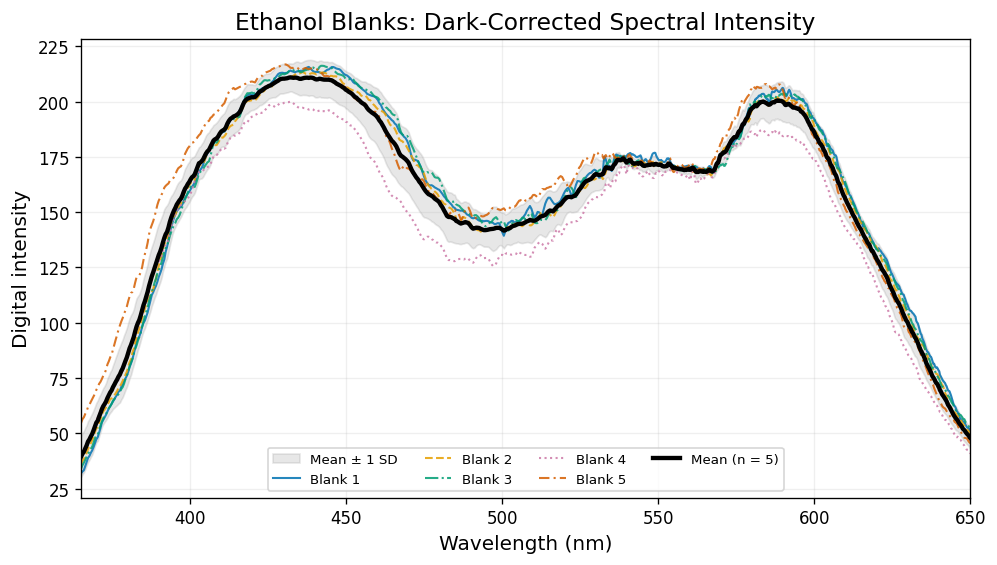


--- SAMPLE AND BLANK PROCESSING SUMMARY ---
Chlorophyllin samples: 30
Ethanol blanks: 5
Calibrated wavelength positions: 847
Positive mean blank positions: 847

--- BLANK QUALITY CONTROL ---


,Blank,Mean_intensity,Median_relative_intensity,Positive_pixels_percent
0,1,157.712495,1.018992,100.0
1,2,155.915862,1.004792,100.0
2,3,157.057932,1.014780,100.0
3,4,145.114072,0.932081,100.0
4,5,158.906199,1.010732,100.0


Median blank CV (%): 4.52

--- SAMPLE QUALITY CONTROL ---


,Concentration_ppm,Replicate,Mean_intensity,Positive_pixels_percent
0,3,1,161.440546,100.0
1,3,2,157.008058,100.0
2,3,3,161.513811,100.0
3,6,1,158.821604,100.0
4,6,2,159.300288,100.0
5,6,3,157.668099,100.0
6,9,1,170.110678,100.0
7,9,2,161.874253,100.0
8,9,3,161.643734,100.0
9,12,1,161.333149,100.0



Dark-corrected sample and blank processing completed.


In [6]:
# ============================================================
# 6. CHLOROPHYLLIN SAMPLE AND BLANK PROCESSING
# ============================================================

# Apply dark-reference correction to all sample photographs
corrected_samples = {}

for ppm in CONCENTRATIONS:
    for replicate in range(1, 4):
        filename = f'{ppm}ppm_Camara_{replicate:02d}_final.jpg'
        corrected_samples[(ppm, replicate)] = subtract_dark(filename)

# Apply dark-reference correction to the five ethanol blanks
corrected_blanks = {}

for i in range(1, 6):
    filename = f'Blk_{i}_Camara_final.jpg'
    corrected_blanks[i] = subtract_dark(filename)

# Extract spectral profiles from the corrected blank images
blank_intensities = np.asarray([
    spectrum_profile(corrected_blanks[i])
    for i in range(1, 6)
])

# Calculate the mean blank intensity and its standard deviation
mean_blank_intensity = blank_intensities.mean(axis=0)

blank_std_intensity = blank_intensities.std(
    axis=0,
    ddof=1
)

# Identify pixels with assigned wavelengths
valid_wavelengths = (
    np.isfinite(wavelengths)
    & (wavelengths >= CAL_MIN)
    & (wavelengths <= CAL_MAX)
)

if not np.any(valid_wavelengths):
    raise ValueError(
        'No calibrated wavelength positions are available.'
    )

# Check whether the reference intensity is positive
valid_blank_signal = (
    valid_wavelengths
    & np.isfinite(mean_blank_intensity)
    & (mean_blank_intensity > 0)
)

if not np.any(valid_blank_signal):
    raise ValueError(
        'The mean ethanol blank contains no valid positive '
        'intensity values in the calibrated interval.'
    )

# Calculate blank variability without dividing by zero
blank_cv = np.divide(
    blank_std_intensity,
    mean_blank_intensity,
    out=np.full_like(mean_blank_intensity, np.nan),
    where=(mean_blank_intensity > 0)
) * 100

# ------------------------------------------------------------
# BLANK QUALITY-CONTROL SUMMARY
# ------------------------------------------------------------

blank_qc_records = []

for i in range(1, 6):

    intensity = blank_intensities[i - 1]

    # Compare each blank with the mean of the five blanks
    relative_intensity = (
        intensity[valid_blank_signal]
        / mean_blank_intensity[valid_blank_signal]
    )

    blank_qc_records.append({
        'Blank': i,
        'Mean_intensity': np.mean(
            intensity[valid_wavelengths]
        ),
        'Median_relative_intensity': np.median(
            relative_intensity
        ),
        'Positive_pixels_percent': (
            100 * np.mean(
                intensity[valid_wavelengths] > 0
            )
        )
    })

df_blank_qc = pd.DataFrame(blank_qc_records)

df_blank_qc.to_csv(
    OUTPUT_DIR / 'Blank_Quality_Control.csv',
    index=False
)

# ------------------------------------------------------------
# SAMPLE QUALITY-CONTROL SUMMARY
# ------------------------------------------------------------

sample_qc_records = []

for ppm in CONCENTRATIONS:
    for replicate in range(1, 4):

        intensity = spectrum_profile(
            corrected_samples[(ppm, replicate)]
        )

        calibrated_intensity = intensity[valid_wavelengths]

        sample_qc_records.append({
            'Concentration_ppm': ppm,
            'Replicate': replicate,
            'Mean_intensity': np.mean(
                calibrated_intensity
            ),
            'Positive_pixels_percent': (
                100 * np.mean(
                    calibrated_intensity > 0
                )
            )
        })

df_sample_qc = pd.DataFrame(sample_qc_records)

df_sample_qc.to_csv(
    OUTPUT_DIR / 'Sample_Quality_Control.csv',
    index=False
)


# ------------------------------------------------------------
# PLOT THE FIVE ETHANOL BLANKS
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.2, 4.6),
    constrained_layout=True
)

blank_colors = [
    CB_PALETTE['blue'],
    CB_PALETTE['orange'],
    CB_PALETTE['bluish_green'],
    CB_PALETTE['reddish_purple'],
    CB_PALETTE['vermillion']
]

blank_line_styles = [
    '-',
    '--',
    '-.',
    ':',
    (0, (5, 2, 1, 2))
]

ax.fill_between(
    wavelengths,
    mean_blank_intensity - blank_std_intensity,
    mean_blank_intensity + blank_std_intensity,
    color=CB_PALETTE['gray'],
    alpha=0.18,
    label='Mean ± 1 SD',
    zorder=1
)

for i, intensity in enumerate(blank_intensities):

    ax.plot(
        wavelengths,
        intensity,
        color=blank_colors[i],
        linestyle=blank_line_styles[i],
        linewidth=1.25,
        alpha=0.85,
        label=f'Blank {i + 1}',
        zorder=2
    )

ax.plot(
    wavelengths,
    mean_blank_intensity,
    color=CB_PALETTE['black'],
    linestyle='-',
    linewidth=2.6,
    label='Mean (n = 5)',
    zorder=3
)

ax.set_title(
    'Ethanol Blanks: Dark-Corrected Spectral Intensity'
)

ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Digital intensity')

ax.set_xlim(CALIBRATED_MIN, CALIBRATED_MAX)

ax.grid(True, alpha=0.20)

ax.legend(
    loc='lower center',
    ncol=4,
    fontsize=8,
    frameon=True
)

plt.savefig(
    OUTPUT_DIR / '02_five_blanks.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# DISPLAY PROCESSING AND QUALITY-CONTROL RESULTS
# ------------------------------------------------------------

print('\n--- SAMPLE AND BLANK PROCESSING SUMMARY ---')

print(f'Chlorophyllin samples: {len(corrected_samples)}')
print(f'Ethanol blanks: {len(corrected_blanks)}')

print(
    f'Calibrated wavelength positions: '
    f'{np.count_nonzero(valid_wavelengths)}'
)

print(
    f'Positive mean blank positions: '
    f'{np.count_nonzero(valid_blank_signal)}'
)

print('\n--- BLANK QUALITY CONTROL ---')

display(df_blank_qc)

print(
    'Median blank CV (%):',
    round(np.nanmedian(blank_cv[valid_blank_signal]), 2)
)

print('\n--- SAMPLE QUALITY CONTROL ---')

display(df_sample_qc)

print(
    '\nDark-corrected sample and blank processing completed.'
)

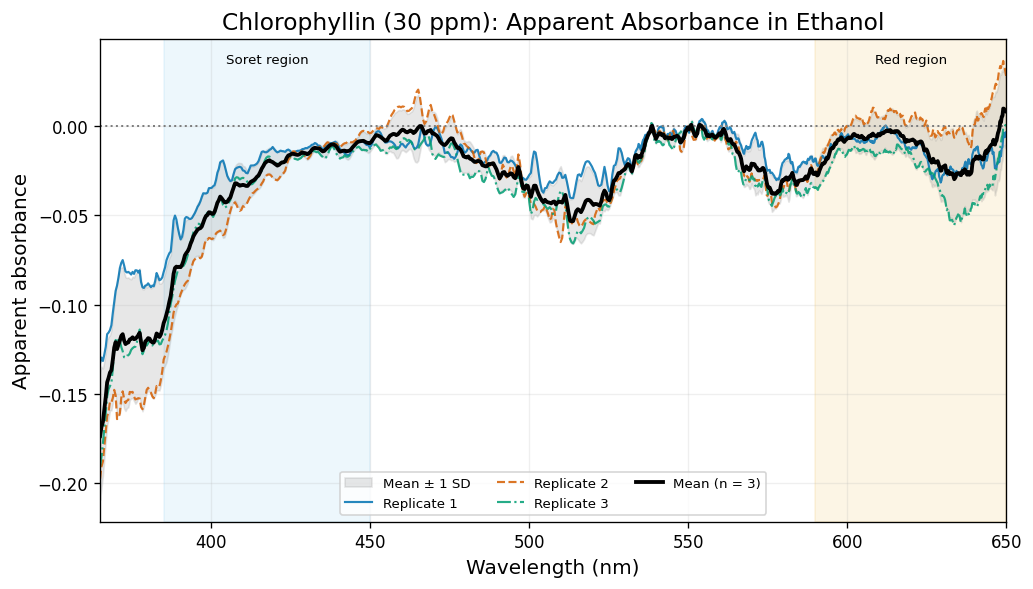


--- DIY CHLOROPHYLLIN PEAK ASSESSMENT ---


,Region,Peak_pixel,Peak_wavelength_nm,Mean_apparent_absorbance,SD_apparent_absorbance,Peak_prominence,Status
0,Soret region,NaN,NaN,NaN,NaN,NaN,No reproducible positive peak detected
1,Red region,NaN,NaN,NaN,NaN,NaN,No reproducible positive peak detected


Estimated high-frequency noise: 0.001103
Minimum peak prominence: 0.003310

--- ORIGINAL COMMERCIAL-WAVELENGTH COMPARISON ---
403 nm target | Assigned wavelength: 402.78 nm | Mean apparent absorbance: -0.0396 | SD: 0.0191
624 nm target | Assigned wavelength: 623.94 nm | Mean apparent absorbance: -0.0118 | SD: 0.0127

IMPORTANT: The independent chlorophyllin sweep was not used in this analysis.
Peak candidates are exploratory and require further experimental verification.
Analytical wavelengths have not been changed.

Peak assessment completed.


In [7]:
# ============================================================
# 7. CHLOROPHYLLIN CALIBRATION-SERIES PEAK ASSESSMENT
# ============================================================

from scipy.signal import find_peaks

# Use only the 30 ppm chlorophyllin calibration photographs acquired in ethanol.
#
# The independent chlorophyllin sweep is NOT used here.
# The reference is the mean of five ethanol blanks.

absorbance_30_replicates = []

for replicate in range(1, 4):

    I = spectrum_profile(
        corrected_samples[(30, replicate)]
    )

    T, A = calculate_absorbance(
        I,
        mean_blank_intensity,
        wavelengths
    )

    absorbance_30_replicates.append(A)

absorbance_30_replicates = np.asarray(
    absorbance_30_replicates
)

# Retain wavelengths with valid absorbance in all replicates.
valid_30 = (
    np.isfinite(wavelengths)
    & np.all(
        np.isfinite(absorbance_30_replicates),
        axis=0
    )
)

if np.count_nonzero(valid_30) < 21:
    raise ValueError(
        'Insufficient valid data for 30 ppm peak assessment.'
    )

peak_wavelengths = wavelengths[valid_30]
peak_pixels = pixels[valid_30]

replicate_values = absorbance_30_replicates[:, valid_30]

mean_30_absorbance = np.mean(
    replicate_values,
    axis=0
)

sd_30_absorbance = np.std(
    replicate_values,
    axis=0,
    ddof=1
)

# Smooth the mean spectrum for exploratory peak detection.
# Raw measurements remain unchanged.
smoothed_30_absorbance = savgol_filter(
    mean_30_absorbance,
    window_length=21,
    polyorder=2
)

# Estimate high-frequency fluctuations.
smoothing_residuals = (
    mean_30_absorbance - smoothed_30_absorbance
)

peak_noise = 1.4826 * np.median(
    np.abs(
        smoothing_residuals
        - np.median(smoothing_residuals)
    )
)

minimum_prominence = max(
    3 * peak_noise,
    1e-6
)

# Search around the absorption regions identified with the commercial spectrophotometer.
# The commercial maxima define search regions only.
peak_regions = {
    'Soret region': (385, 450),
    'Red region': (590, 650)
}

peak_records = []

for region, (lo, hi) in peak_regions.items():

    idx = np.flatnonzero(
        (peak_wavelengths >= lo)
        & (peak_wavelengths <= hi)
    )

    if len(idx) < 3:
        raise ValueError(
            f'Insufficient calibrated data in {region}.'
        )

    regional_profile = smoothed_30_absorbance[idx]

    peaks, properties = find_peaks(
        regional_profile,
        prominence=minimum_prominence,
        distance=8
    )

    accepted = []

    for j, local_peak in enumerate(peaks):

        position = idx[local_peak]

        # A candidate must show positive apparent absorbance in all three 30 ppm replicates.
        positive_replicates = np.all(
            replicate_values[:, position] > 0
        )

        # The mean signal must exceed twice the between-replicate standard deviation.
        reproducible_signal = (
            smoothed_30_absorbance[position]
            > 2 * sd_30_absorbance[position]
        )

        if (
            smoothed_30_absorbance[position] > 0
            and positive_replicates
            and reproducible_signal
        ):
            accepted.append(j)

    if accepted:

        best = max(
            accepted,
            key=lambda j: regional_profile[peaks[j]]
        )

        position = idx[peaks[best]]

        peak_records.append({
            'Region': region,
            'Peak_pixel': int(peak_pixels[position]),
            'Peak_wavelength_nm': float(
                peak_wavelengths[position]
            ),
            'Mean_apparent_absorbance': float(
                mean_30_absorbance[position]
            ),
            'SD_apparent_absorbance': float(
                sd_30_absorbance[position]
            ),
            'Peak_prominence': float(
                properties['prominences'][best]
            ),
            'Status': 'Exploratory candidate'
        })

    else:

        peak_records.append({
            'Region': region,
            'Peak_pixel': np.nan,
            'Peak_wavelength_nm': np.nan,
            'Mean_apparent_absorbance': np.nan,
            'SD_apparent_absorbance': np.nan,
            'Peak_prominence': np.nan,
            'Status': 'No reproducible positive peak detected'
        })


# ------------------------------------------------------------
# PLOT THE THREE REPLICATES AND MEAN ABSORBANCE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.5, 4.8),
    constrained_layout=True
)

replicate_colors = [
    CB_PALETTE['blue'],
    CB_PALETTE['vermillion'],
    CB_PALETTE['bluish_green']
]

replicate_styles = [
    '-',
    '--',
    '-.'
]

# Highlight the spectral search regions.
ax.axvspan(
    385, 450,
    color=CB_PALETTE['sky_blue'],
    alpha=0.10,
    zorder=0
)

ax.axvspan(
    590, 650,
    color=CB_PALETTE['orange'],
    alpha=0.10,
    zorder=0
)

# Display the mean ± SD interval.
ax.fill_between(
    peak_wavelengths,
    mean_30_absorbance - sd_30_absorbance,
    mean_30_absorbance + sd_30_absorbance,
    color=CB_PALETTE['gray'],
    alpha=0.18,
    label='Mean ± 1 SD',
    zorder=1
)

# Plot the three independent 30 ppm measurements.
for replicate in range(1, 4):

    ax.plot(
        peak_wavelengths,
        replicate_values[replicate - 1],
        color=replicate_colors[replicate - 1],
        linestyle=replicate_styles[replicate - 1],
        linewidth=1.3,
        alpha=0.85,
        label=f'Replicate {replicate}',
        zorder=2
    )

# Highlight the mean apparent absorbance spectrum.
ax.plot(
    peak_wavelengths,
    mean_30_absorbance,
    color=CB_PALETTE['black'],
    linestyle='-',
    linewidth=2.3,
    label='Mean (n = 3)',
    zorder=3
)

# Mark the zero-absorbance reference line.
ax.axhline(
    0,
    color=CB_PALETTE['gray'],
    linestyle=':',
    linewidth=1.2
)

# Label the search windows directly.
ax.text(
    417.5, 0.97,
    'Soret region',
    transform=ax.get_xaxis_transform(),
    ha='center',
    va='top',
    fontsize=8
)

ax.text(
    620, 0.97,
    'Red region',
    transform=ax.get_xaxis_transform(),
    ha='center',
    va='top',
    fontsize=8
)

# Mark identified candidates if any were detected.
for record in peak_records:

    if np.isfinite(record['Peak_wavelength_nm']):

        nm = record['Peak_wavelength_nm']

        position = np.argmin(
            np.abs(peak_wavelengths - nm)
        )

        ax.scatter(
            nm,
            smoothed_30_absorbance[position],
            color=CB_PALETTE['vermillion'],
            marker='D',
            edgecolors='black',
            linewidths=0.5,
            s=60,
            zorder=5,
            label='Peak candidate'
        )

        ax.annotate(
            f'{nm:.1f} nm',
            (
                nm,
                smoothed_30_absorbance[position]
            ),
            xytext=(7, 8),
            textcoords='offset points',
            fontsize=8
        )

# Format the figure.
ax.set_title(
    'Chlorophyllin (30 ppm): Apparent Absorbance in Ethanol'
)

ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Apparent absorbance')

ax.set_xlim(
    CALIBRATED_MIN,
    CALIBRATED_MAX
)

ax.grid(True, alpha=0.20)

ax.legend(
    loc='lower center',
    ncol=3,
    fontsize=8,
    frameon=True
)

plt.savefig(
    OUTPUT_DIR / 'DIY_Chlorophyllin_30ppm_Peak_Assessment.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# EXPORT THE EXPLORATORY PEAK ASSESSMENT
# ------------------------------------------------------------

df_diy_peaks = pd.DataFrame(peak_records)

df_diy_peaks.to_csv(
    OUTPUT_DIR / 'DIY_Chlorophyllin_30ppm_Peak_Candidates.csv',
    index=False
)

print('\n--- DIY CHLOROPHYLLIN PEAK ASSESSMENT ---')

display(df_diy_peaks)

print(
    f'Estimated high-frequency noise: {peak_noise:.6f}'
)

print(
    f'Minimum peak prominence: {minimum_prominence:.6f}'
)

print('\n--- ORIGINAL COMMERCIAL-WAVELENGTH COMPARISON ---')

for nm, pixel in target_pixels.items():

    values = absorbance_30_replicates[:, pixel]

    print(
        f'{nm} nm target | '
        f'Assigned wavelength: {wavelengths[pixel]:.2f} nm | '
        f'Mean apparent absorbance: {np.mean(values):.4f} | '
        f'SD: {np.std(values, ddof=1):.4f}'
    )

print(
    '\nIMPORTANT: The independent chlorophyllin sweep was not used in this analysis.'
)

print(
    'Peak candidates are exploratory and require further experimental verification.'
)

print(
    'Analytical wavelengths have not been changed.'
)

print('\nPeak assessment completed.')

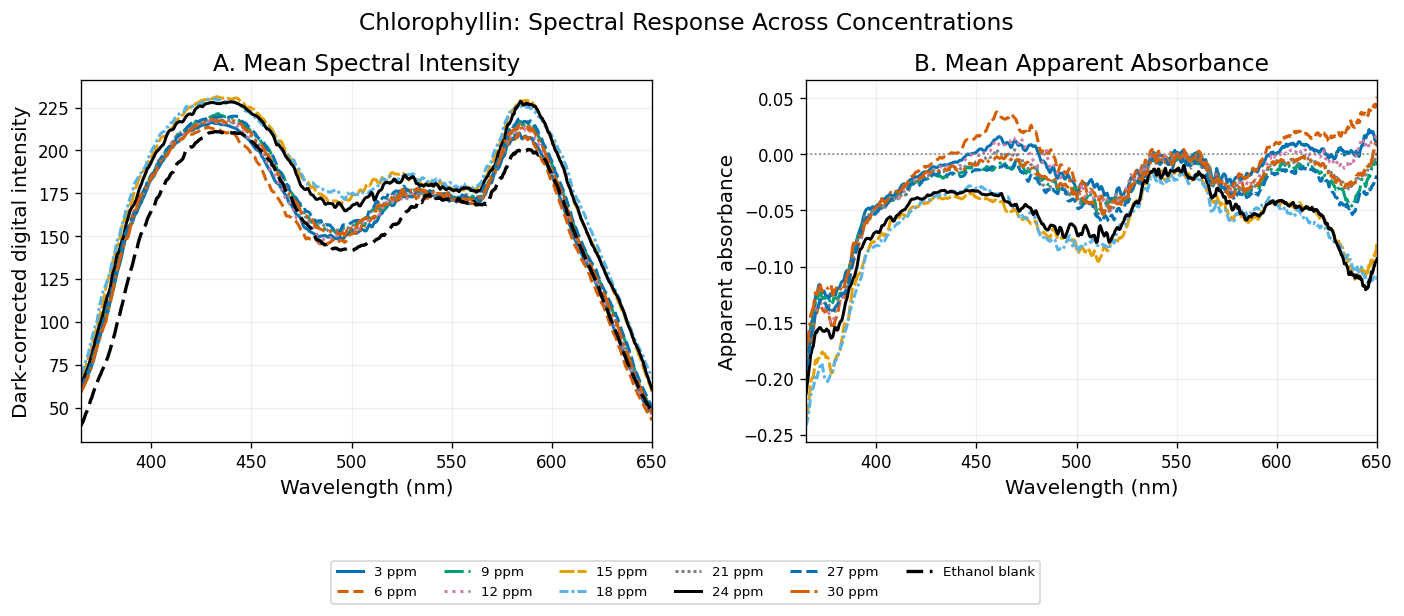

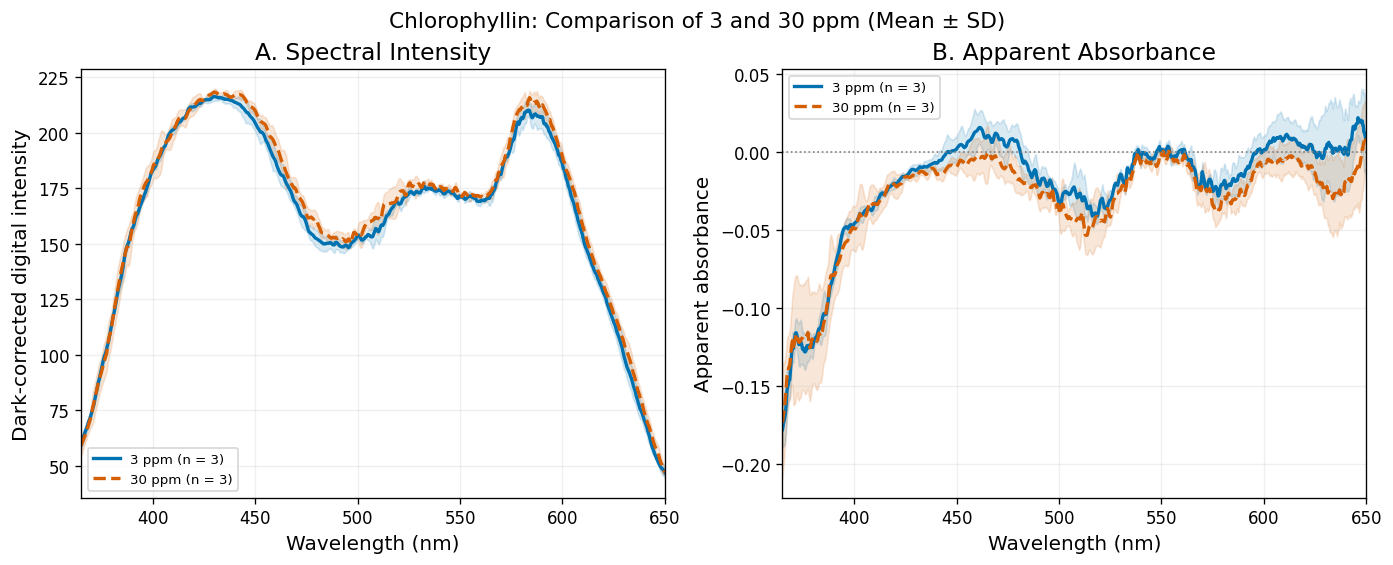


--- CHLOROPHYLLIN SPECTRAL COMPARISON ---
Concentrations: 10
Individual measurements: 30
Calibrated spectral positions: 847

--- CONCENTRATION-LEVEL SIGNAL DIAGNOSTICS ---


,Concentration_ppm,Mean_intensity,SD_between_replicates,Mean_negative_absorbance_percent
0,3,159.9875,2.5805,72.2550
1,6,158.5967,0.8390,55.3719
2,9,164.5429,4.8232,93.0342
3,12,161.7887,2.8434,76.2298
4,15,176.4879,15.6471,99.5671
5,18,178.1514,27.8076,84.9665
6,21,163.6682,4.1550,83.2349
7,24,174.5233,14.4462,99.8032
8,27,165.6844,2.9624,98.8194
9,30,163.1979,2.0446,91.6175



--- DATA INTERPRETATION NOTES ---
No analytical wavelength or absorption maximum was selected for concentration comparison.
All 30 individual spectral profiles were retained.
Spectral mean and SD were calculated from three replicates per concentration.
Negative apparent absorbance values were preserved.
Spectral differences do not by themselves establish reliable concentration discrimination.

Full-spectrum comparison completed successfully.


In [8]:
# ============================================================
# 8. COMPARISON OF CHLOROPHYLLIN SPECTRA ACROSS CONCENTRATIONS
# ============================================================

# Explore whether the DIY spectrophotometer produces distinguishable spectral responses for different
# chlorophyllin concentrations.
#
# No analytical wavelengths or absorption maxima are selected.
# All 30 measurements are retained.
# Apparent absorbance is treated as an exploratory signal.

# ------------------------------------------------------------
# DEFINE THE EVALUATED SPECTRAL INTERVAL
# ------------------------------------------------------------

valid_spectral_pixels = np.flatnonzero(
    np.isfinite(wavelengths)
    & (wavelengths >= CAL_MIN)
    & (wavelengths <= CAL_MAX)
    & np.isfinite(mean_blank_intensity)
    & (mean_blank_intensity > 0)
)

if len(valid_spectral_pixels) < 20:
    raise ValueError(
        'Insufficient calibrated spectral data.'
    )

selected_wavelengths = wavelengths[valid_spectral_pixels]

# ------------------------------------------------------------
# PROCESS ALL 30 CHLOROPHYLLIN MEASUREMENTS
# ------------------------------------------------------------

sample_profiles = {}
sample_transmittances = {}
sample_absorbances = {}

spectral_records = []
signal_records = []

for ppm in CONCENTRATIONS:
    for replicate in range(1, 4):

        # Extract the dark-corrected digital intensity.
        I = spectrum_profile(
            corrected_samples[(ppm, replicate)]
        )

        # Calculate apparent transmittance and absorbance against the mean of five ethanol blanks.
        T, A = calculate_absorbance(
            I,
            mean_blank_intensity,
            wavelengths
        )

        sample_profiles[(ppm, replicate)] = I
        sample_transmittances[(ppm, replicate)] = T
        sample_absorbances[(ppm, replicate)] = A

        # Preserve all calibrated spectral measurements.
        table = pd.DataFrame({
            'Concentration_ppm': ppm,
            'Replicate': replicate,
            'Pixel': valid_spectral_pixels,
            'Wavelength_nm': selected_wavelengths,
            'Sample_intensity': I[valid_spectral_pixels],
            'Blank_intensity':
                mean_blank_intensity[valid_spectral_pixels],
            'Intensity_difference':
                mean_blank_intensity[valid_spectral_pixels]
                - I[valid_spectral_pixels],
            'Transmittance': T[valid_spectral_pixels],
            'Apparent_absorbance': A[valid_spectral_pixels]
        })

        spectral_records.append(table)

        # Calculate whole-spectrum diagnostic indicators.
        valid_A = np.isfinite(
            A[valid_spectral_pixels]
        )

        negative_percent = (
            100 * np.mean(
                A[valid_spectral_pixels][valid_A] < 0
            )
            if np.any(valid_A)
            else np.nan
        )

        signal_records.append({
            'Concentration_ppm': ppm,
            'Replicate': replicate,
            'Mean_intensity': float(
                np.mean(I[valid_spectral_pixels])
            ),
            'SD_intensity_across_pixels': float(
                np.std(
                    I[valid_spectral_pixels],
                    ddof=1
                )
            ),
            'Valid_absorbance_pixels': int(
                np.count_nonzero(valid_A)
            ),
            'Negative_absorbance_percent':
                negative_percent
        })

# Export individual measurements without averaging or excluding anomalous replicates.
df_all_spectra = pd.concat(
    spectral_records,
    ignore_index=True
)

df_all_spectra.to_csv(
    OUTPUT_DIR / 'Chlorophyllin_All_Replicate_Spectra.csv',
    index=False
)

df_signal_summary = pd.DataFrame(signal_records)

df_signal_summary.to_csv(
    OUTPUT_DIR / 'Chlorophyllin_Signal_Diagnostics.csv',
    index=False
)

# ------------------------------------------------------------
# CALCULATE MEAN SPECTRA AND REPLICATE VARIABILITY
# ------------------------------------------------------------

spectral_summary_records = []

for ppm in CONCENTRATIONS:

    # Intensity profiles from three replicates
    intensity_stack = np.asarray([
        sample_profiles[(ppm, rep)][valid_spectral_pixels]
        for rep in range(1, 4)
    ])

    # Apparent absorbance profiles from three replicates
    absorbance_stack = np.asarray([
        sample_absorbances[(ppm, rep)][valid_spectral_pixels]
        for rep in range(1, 4)
    ])

    mean_intensity = intensity_stack.mean(axis=0)

    sd_intensity = intensity_stack.std(
        axis=0,
        ddof=1
    )

    # Calculate summary absorbance only at positions with valid results for all three replicates.
    valid_group = np.all(
        np.isfinite(absorbance_stack),
        axis=0
    )

    mean_absorbance = np.full(
        len(valid_spectral_pixels),
        np.nan
    )

    sd_absorbance = np.full(
        len(valid_spectral_pixels),
        np.nan
    )

    mean_absorbance[valid_group] = (
        absorbance_stack[:, valid_group].mean(axis=0)
    )

    sd_absorbance[valid_group] = (
        absorbance_stack[:, valid_group].std(
            axis=0,
            ddof=1
        )
    )

    summary_table = pd.DataFrame({
        'Concentration_ppm': ppm,
        'Wavelength_nm': selected_wavelengths,
        'Mean_intensity': mean_intensity,
        'SD_intensity': sd_intensity,
        'Mean_apparent_absorbance': mean_absorbance,
        'SD_apparent_absorbance': sd_absorbance,
        'Valid_replicate_count': np.sum(
            np.isfinite(absorbance_stack),
            axis=0
        )
    })

    spectral_summary_records.append(summary_table)

df_spectral_summary = pd.concat(
    spectral_summary_records,
    ignore_index=True
)

df_spectral_summary.to_csv(
    OUTPUT_DIR / 'Chlorophyllin_Concentration_Spectral_Summary.csv',
    index=False
)


# ============================================================
# FIGURE 8A: MEAN SPECTRA OF ALL TEN CONCENTRATIONS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5.2)
)

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.87,
    bottom=0.29,
    wspace=0.27
)

for i, ppm in enumerate(CONCENTRATIONS):

    data = df_spectral_summary[
        df_spectral_summary['Concentration_ppm'] == ppm
    ]

    x = data['Wavelength_nm'].to_numpy()

    style = get_concentration_style(i)

    # Panel A: mean dark-corrected spectral intensity.
    axes[0].plot(
        x,
        data['Mean_intensity'].to_numpy(),
        label=f'{ppm} ppm',
        **style
    )

    # Panel B: mean apparent absorbance.
    axes[1].plot(
        x,
        data['Mean_apparent_absorbance'].to_numpy(),
        **style
    )

axes[0].plot(
    selected_wavelengths,
    mean_blank_intensity[valid_spectral_pixels],
    color=CB_PALETTE['black'],
    linestyle=(0, (5, 2)),
    linewidth=2,
    label='Ethanol blank'
)

axes[0].set_title(
    'A. Mean Spectral Intensity'
)

axes[0].set_ylabel(
    'Dark-corrected digital intensity'
)

axes[1].set_title(
    'B. Mean Apparent Absorbance'
)

axes[1].set_ylabel(
    'Apparent absorbance'
)

axes[1].axhline(
    0,
    color=CB_PALETTE['gray'],
    linestyle=':',
    linewidth=1
)

for ax in axes:
    ax.set_xlim(
        CALIBRATED_MIN,
        CALIBRATED_MAX
    )
    ax.set_xlabel('Wavelength (nm)')
    ax.grid(True, alpha=0.20)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.02),
    ncol=6,
    fontsize=8,
    frameon=True
)

fig.suptitle(
    'Chlorophyllin: Spectral Response Across Concentrations',
    fontsize=14
)

plt.savefig(
    OUTPUT_DIR / '03a_chlorophyllin_concentration_spectra.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ============================================================
# FIGURE 8B: LOWEST VS HIGHEST CONCENTRATION
# ============================================================

# Compare 3 ppm and 30 ppm using mean spectra and standard deviation from three replicates.

fig, axes = plt.subplots(
    1, 2,
    figsize=(11.5, 4.6),
    constrained_layout=True
)

comparison_styles = {
    3: {
        'color': CB_PALETTE['blue'],
        'linestyle': '-'
    },
    30: {
        'color': CB_PALETTE['vermillion'],
        'linestyle': '--'
    }
}

for ppm in (3, 30):

    data = df_spectral_summary[
        df_spectral_summary['Concentration_ppm'] == ppm
    ]

    x = data['Wavelength_nm'].to_numpy()

    mean_I = data['Mean_intensity'].to_numpy()
    sd_I = data['SD_intensity'].to_numpy()

    mean_A = data[
        'Mean_apparent_absorbance'
    ].to_numpy()

    sd_A = data[
        'SD_apparent_absorbance'
    ].to_numpy()

    style = comparison_styles[ppm]

    # Panel A: intensity with standard deviation.
    axes[0].plot(
        x,
        mean_I,
        color=style['color'],
        linestyle=style['linestyle'],
        linewidth=2,
        label=f'{ppm} ppm (n = 3)'
    )

    axes[0].fill_between(
        x,
        mean_I - sd_I,
        mean_I + sd_I,
        color=style['color'],
        alpha=0.15
    )

    # Panel B: apparent absorbance with SD.
    axes[1].plot(
        x,
        mean_A,
        color=style['color'],
        linestyle=style['linestyle'],
        linewidth=2,
        label=f'{ppm} ppm (n = 3)'
    )

    axes[1].fill_between(
        x,
        mean_A - sd_A,
        mean_A + sd_A,
        color=style['color'],
        alpha=0.15
    )

axes[0].set_title(
    'A. Spectral Intensity'
)

axes[0].set_ylabel(
    'Dark-corrected digital intensity'
)

axes[1].set_title(
    'B. Apparent Absorbance'
)

axes[1].set_ylabel(
    'Apparent absorbance'
)

axes[1].axhline(
    0,
    color=CB_PALETTE['gray'],
    linestyle=':',
    linewidth=1
)

for ax in axes:

    ax.set_xlim(
        CALIBRATED_MIN,
        CALIBRATED_MAX
    )

    ax.set_xlabel('Wavelength (nm)')

    ax.grid(True, alpha=0.20)

    ax.legend(
        loc='best',
        fontsize=8
    )

fig.suptitle(
    'Chlorophyllin: Comparison of 3 and 30 ppm (Mean ± SD)',
    fontsize=13
)

plt.savefig(
    OUTPUT_DIR / '03b_chlorophyllin_3_vs_30ppm.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# RETAIN ORIGINAL 30 PPM VARIABLES FOR COMPATIBILITY
# ------------------------------------------------------------

sample_30_intensity = sample_profiles[(30, 1)]

transmittance_30 = sample_transmittances[(30, 1)]

absorbance_30 = sample_absorbances[(30, 1)]

df_30 = pd.DataFrame({
    'Pixel': pixels,
    'Wavelength_nm': wavelengths,
    'Sample_intensity': sample_30_intensity,
    'Blank_intensity': mean_blank_intensity,
    'Transmittance': transmittance_30,
    'Transmittance_percent': 100 * transmittance_30,
    'Absorbance': absorbance_30
})

df_30.to_csv(
    OUTPUT_DIR / 'Chlorophyllin_30ppm_Replicate1.csv',
    index=False
)

# ------------------------------------------------------------
# CONCENTRATION-LEVEL SIGNAL DIAGNOSTICS
# ------------------------------------------------------------

df_concentration_overview = (
    df_signal_summary
    .groupby('Concentration_ppm')
    .agg(
        Mean_intensity=('Mean_intensity', 'mean'),
        SD_between_replicates=('Mean_intensity', 'std'),
        Mean_negative_absorbance_percent=(
            'Negative_absorbance_percent',
            'mean'
        )
    )
    .reset_index()
)

df_concentration_overview.to_csv(
    OUTPUT_DIR / 'Chlorophyllin_Concentration_Overview.csv',
    index=False
)

print('\n--- CHLOROPHYLLIN SPECTRAL COMPARISON ---')

print(f'Concentrations: {len(CONCENTRATIONS)}')
print(f'Individual measurements: {len(sample_profiles)}')
print(f'Calibrated spectral positions: {len(valid_spectral_pixels)}')

print('\n--- CONCENTRATION-LEVEL SIGNAL DIAGNOSTICS ---')

display(df_concentration_overview.round(4))

print('\n--- DATA INTERPRETATION NOTES ---')

print(
    'No analytical wavelength or absorption maximum was selected for concentration comparison.'
)

print(
    'All 30 individual spectral profiles were retained.'
)

print(
    'Spectral mean and SD were calculated from three replicates per concentration.'
)

print(
    'Negative apparent absorbance values were preserved.'
)

print(
    'Spectral differences do not by themselves establish reliable concentration discrimination.'
)

print(
    '\nFull-spectrum comparison completed successfully.'
)

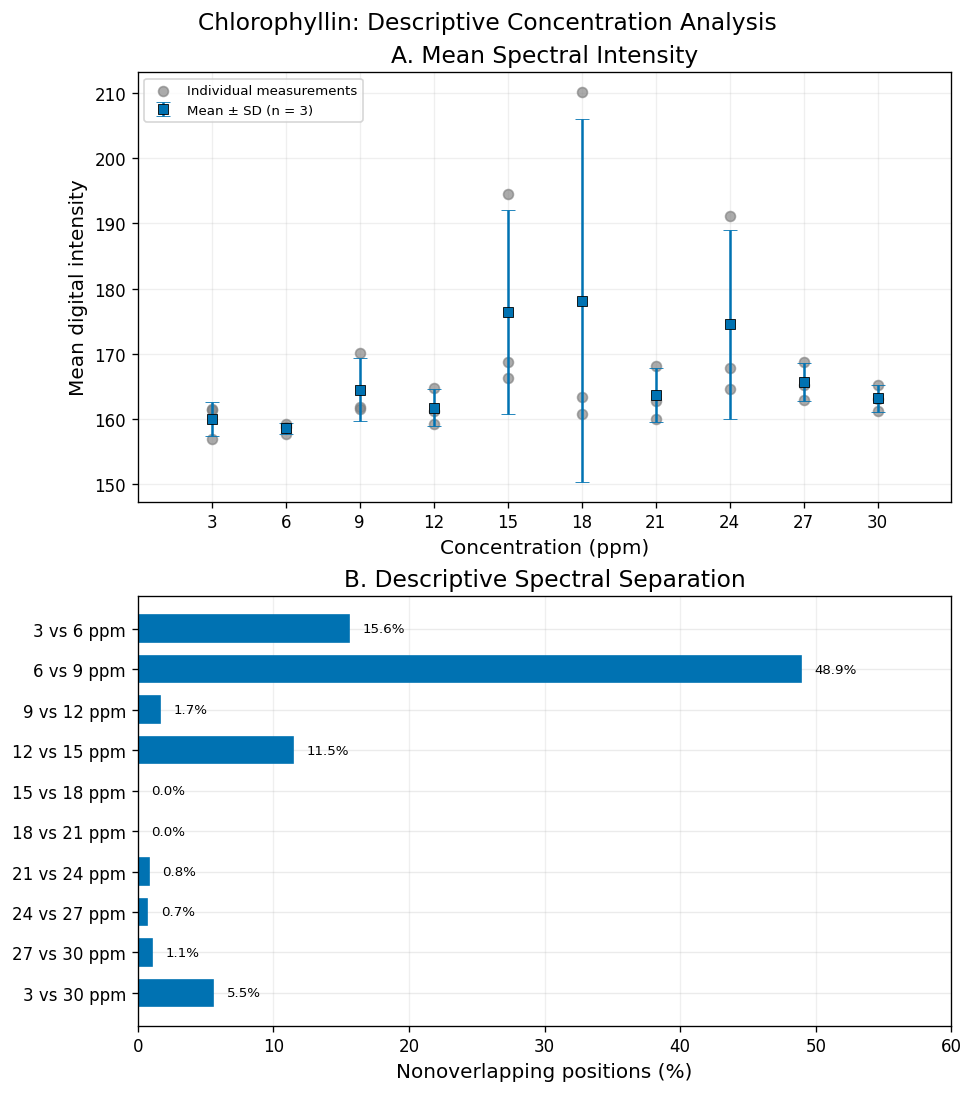


--- BASIC DESCRIPTIVE STATISTICS ---


,Concentration_ppm,N,Mean_intensity,SD_intensity,CV_percent
0,3,3,159.9875,2.5805,1.6129
1,6,3,158.5967,0.8390,0.5290
2,9,3,164.5429,4.8232,2.9313
3,12,3,161.7887,2.8434,1.7575
4,15,3,176.4879,15.6471,8.8658
5,18,3,178.1514,27.8076,15.6090
6,21,3,163.6682,4.1550,2.5386
7,24,3,174.5233,14.4462,8.2775
8,27,3,165.6844,2.9624,1.7880
9,30,3,163.1979,2.0446,1.2528



--- FULL-SPECTRUM DESCRIPTIVE COMPARISON ---


,Concentration_1_ppm,Concentration_2_ppm,Valid_wavelength_positions,Nonoverlapping_SD_intervals_percent,Mean_absolute_spectral_difference,Mean_replicate_SD
0,3,6,847,15.5844,2.8856,2.2839
1,6,9,847,48.8784,6.4414,3.2705
2,9,12,847,1.6529,3.2127,4.1740
3,12,15,847,11.4522,14.6992,9.5206
4,15,18,847,0.0000,2.8312,21.7748
5,18,21,847,0.0000,14.4833,16.2058
6,21,24,847,0.8264,10.8551,9.5275
7,24,27,847,0.7084,8.8390,8.8757
8,27,30,847,1.0626,2.5988,3.4132
9,3,30,847,5.5490,3.3360,3.3007



--- LOWEST VS HIGHEST CONCENTRATION ---
Lowest concentration: 3 ppm
Mean intensity ± SD: 159.99 ± 2.58
Highest concentration: 30 ppm
Mean intensity ± SD: 163.20 ± 2.04
Absolute difference between means: 3.21 digital units
Mean ± SD intervals overlap: True

--- INTERPRETATION NOTES ---
Mean, SD, and CV describe the variability of three measurements per concentration.
Spectral interval overlap is descriptive and does not constitute a hypothesis test.
Correlated spectral pixels are not independent experimental replicates.
Differences in digital intensity may reflect illumination or acquisition variability.
No concentration calibration or analytical method validation was performed.

Basic statistical analysis completed successfully.


In [9]:
# ============================================================
# 9. BASIC STATISTICAL ANALYSIS OF CHLOROPHYLLIN CONCENTRATIONS
# ============================================================

# Evaluate whether the DIY spectrophotometer can distinguish different chlorophyllin concentrations using basic
# descriptive statistics and complete spectral profiles.
#
# Statistical methods:
# - Arithmetic mean
# - Standard deviation (SD)
# - Coefficient of variation (CV%)
# - Descriptive comparison of mean ± SD spectral intervals

# ------------------------------------------------------------
# CALCULATE BASIC STATISTICS FOR EACH CONCENTRATION
# ------------------------------------------------------------

# Use the mean spectral intensity of each individual image.
# These values were calculated before.

df_basic_stats = (
    df_signal_summary
    .groupby('Concentration_ppm')['Mean_intensity']
    .agg(['count', 'mean', 'std'])
    .reset_index()
)

df_basic_stats.columns = [
    'Concentration_ppm',
    'N',
    'Mean_intensity',
    'SD_intensity'
]

# Calculate the coefficient of variation.
df_basic_stats['CV_percent'] = (
    100
    * df_basic_stats['SD_intensity']
    / df_basic_stats['Mean_intensity']
)

# Confirm that all concentrations have three replicates.
if not np.all(df_basic_stats['N'] == 3):
    raise ValueError(
        'Expected three measurements per concentration.'
    )

df_basic_stats.to_csv(
    OUTPUT_DIR / 'Chlorophyllin_Basic_Statistics.csv',
    index=False
)


# ------------------------------------------------------------
# DESCRIPTIVE COMPARISON OF COMPLETE SPECTRAL PROFILES
# ------------------------------------------------------------

# Compare the mean ± SD bands of complete spectra.
#
# For each wavelength, determine whether the intervals of two concentrations overlap.
#

spectral_overlap_records = []

# Compare adjacent concentrations and the two extremes.
concentration_pairs = list(
    zip(CONCENTRATIONS[:-1], CONCENTRATIONS[1:])
)

concentration_pairs.append(
    (CONCENTRATIONS[0], CONCENTRATIONS[-1])
)

for ppm_1, ppm_2 in concentration_pairs:

    data_1 = (
        df_spectral_summary[
            df_spectral_summary['Concentration_ppm'] == ppm_1
        ]
        .sort_values('Wavelength_nm')
    )

    data_2 = (
        df_spectral_summary[
            df_spectral_summary['Concentration_ppm'] == ppm_2
        ]
        .sort_values('Wavelength_nm')
    )

    x1 = data_1['Wavelength_nm'].to_numpy()
    x2 = data_2['Wavelength_nm'].to_numpy()

    if (
        len(x1) != len(x2)
        or not np.allclose(x1, x2)
    ):
        raise ValueError(
            'Spectral wavelength grids are not compatible.'
        )

    mean_1 = data_1['Mean_intensity'].to_numpy()
    mean_2 = data_2['Mean_intensity'].to_numpy()

    sd_1 = data_1['SD_intensity'].to_numpy()
    sd_2 = data_2['SD_intensity'].to_numpy()

    valid = (
        np.isfinite(mean_1)
        & np.isfinite(mean_2)
        & np.isfinite(sd_1)
        & np.isfinite(sd_2)
    )

    # Construct mean ± SD intervals.
    lower_1 = mean_1 - sd_1
    upper_1 = mean_1 + sd_1

    lower_2 = mean_2 - sd_2
    upper_2 = mean_2 + sd_2

    # Identify positions where the intervals do not overlap.
    no_overlap = (
        (upper_1 < lower_2)
        | (upper_2 < lower_1)
    )

    n_valid = int(np.count_nonzero(valid))

    if n_valid == 0:
        raise ValueError(
            'No valid spectral positions for comparison.'
        )

    nonoverlap_percent = (
        100 * np.count_nonzero(no_overlap & valid) / n_valid
    )

    mean_absolute_difference = float(
        np.mean(
            np.abs(mean_1[valid] - mean_2[valid])
        )
    )

    mean_replicate_SD = float(
        np.mean(
            (sd_1[valid] + sd_2[valid]) / 2
        )
    )

    spectral_overlap_records.append({
        'Concentration_1_ppm': ppm_1,
        'Concentration_2_ppm': ppm_2,
        'Valid_wavelength_positions': n_valid,
        'Nonoverlapping_SD_intervals_percent':
            nonoverlap_percent,
        'Mean_absolute_spectral_difference':
            mean_absolute_difference,
        'Mean_replicate_SD':
            mean_replicate_SD
    })

df_spectral_overlap = pd.DataFrame(
    spectral_overlap_records
)

df_spectral_overlap.to_csv(
    OUTPUT_DIR / 'Chlorophyllin_Spectral_Overlap.csv',
    index=False
)


# ============================================================
# FIGURE 9. COMPACT DESCRIPTIVE STATISTICS
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(8, 9),
    constrained_layout=True
)

# ------------------------------------------------------------
# PANEL A: MEAN SPECTRAL INTENSITY
# ------------------------------------------------------------

ax = axes[0]

first_point = True

for ppm in CONCENTRATIONS:

    measurements = df_signal_summary.loc[
        df_signal_summary['Concentration_ppm'] == ppm,
        'Mean_intensity'
    ].to_numpy()

    ax.scatter(
        np.full(len(measurements), ppm),
        measurements,
        color=CB_PALETTE['gray'],
        marker='o',
        s=35,
        alpha=0.65,
        label='Individual measurements' if first_point else None,
        zorder=2
    )

    first_point = False

ax.errorbar(
    df_basic_stats['Concentration_ppm'],
    df_basic_stats['Mean_intensity'],
    yerr=df_basic_stats['SD_intensity'],
    fmt='s',
    linestyle='none',
    color=CB_PALETTE['blue'],
    markeredgecolor=CB_PALETTE['black'],
    markeredgewidth=0.5,
    markersize=6,
    capsize=4,
    elinewidth=1.5,
    label='Mean ± SD (n = 3)',
    zorder=3
)

ax.set_title('A. Mean Spectral Intensity')
ax.set_xlabel('Concentration (ppm)')
ax.set_ylabel('Mean digital intensity')

ax.set_xticks(CONCENTRATIONS)
ax.set_xlim(0, 33)

ax.grid(True, alpha=0.20)
ax.legend(loc='upper left', fontsize=8)

# ------------------------------------------------------------
# PANEL B: DESCRIPTIVE SPECTRAL SEPARATION
# ------------------------------------------------------------

ax = axes[1]

comparison_labels = [
    f'{int(a)} vs {int(b)} ppm'
    for a, b in zip(
        df_spectral_overlap['Concentration_1_ppm'],
        df_spectral_overlap['Concentration_2_ppm']
    )
]

overlap_values = df_spectral_overlap[
    'Nonoverlapping_SD_intervals_percent'
].to_numpy(dtype=float)

positions = np.arange(len(comparison_labels))

ax.barh(
    positions,
    overlap_values,
    height=0.65,
    color=CB_PALETTE['blue'],
    edgecolor=CB_PALETTE['blue']
)

ax.set_yticks(positions)
ax.set_yticklabels(comparison_labels)

ax.invert_yaxis()

ax.set_title('B. Descriptive Spectral Separation')
ax.set_xlabel('Nonoverlapping positions (%)')

axis_max = max(
    60,
    10 * np.ceil(np.max(overlap_values) / 10) + 10
)

ax.set_xlim(0, axis_max)

for position, value in zip(positions, overlap_values):

    ax.text(
        value + 1,
        position,
        f'{value:.1f}%',
        ha='left',
        va='center',
        fontsize=8,
        color=CB_PALETTE['black']
    )

ax.grid(axis='x', alpha=0.20)
ax.set_axisbelow(True)

# ------------------------------------------------------------
# EXPORT THE COMBINED FIGURE
# ------------------------------------------------------------

fig.suptitle(
    'Chlorophyllin: Descriptive Concentration Analysis',
    fontsize=14
)

plt.savefig(
    OUTPUT_DIR / '04_chlorophyllin_descriptive_statistics.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# COMPARE THE LOWEST AND HIGHEST CONCENTRATIONS
# ------------------------------------------------------------

lowest = df_basic_stats.loc[
    df_basic_stats['Concentration_ppm']
    == CONCENTRATIONS[0]
].iloc[0]

highest = df_basic_stats.loc[
    df_basic_stats['Concentration_ppm']
    == CONCENTRATIONS[-1]
].iloc[0]

mean_difference = abs(
    highest['Mean_intensity']
    - lowest['Mean_intensity']
)

lower_lowest = (
    lowest['Mean_intensity'] - lowest['SD_intensity']
)

upper_lowest = (
    lowest['Mean_intensity'] + lowest['SD_intensity']
)

lower_highest = (
    highest['Mean_intensity'] - highest['SD_intensity']
)

upper_highest = (
    highest['Mean_intensity'] + highest['SD_intensity']
)

intervals_overlap = (
    lower_lowest <= upper_highest
    and lower_highest <= upper_lowest
)

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print('\n--- BASIC DESCRIPTIVE STATISTICS ---')

display(df_basic_stats.round(4))

print('\n--- FULL-SPECTRUM DESCRIPTIVE COMPARISON ---')

display(df_spectral_overlap.round(4))

print('\n--- LOWEST VS HIGHEST CONCENTRATION ---')

print(
    f'Lowest concentration: {CONCENTRATIONS[0]} ppm'
)

print(
    f'Mean intensity ± SD: '
    f'{lowest["Mean_intensity"]:.2f} ± '
    f'{lowest["SD_intensity"]:.2f}'
)

print(
    f'Highest concentration: {CONCENTRATIONS[-1]} ppm'
)

print(
    f'Mean intensity ± SD: '
    f'{highest["Mean_intensity"]:.2f} ± '
    f'{highest["SD_intensity"]:.2f}'
)

print(
    f'Absolute difference between means: '
    f'{mean_difference:.2f} digital units'
)

print(
    f'Mean ± SD intervals overlap: {intervals_overlap}'
)

print('\n--- INTERPRETATION NOTES ---')

print(
    'Mean, SD, and CV describe the variability of three measurements per concentration.'
)

print(
    'Spectral interval overlap is descriptive and does not constitute a hypothesis test.'
)

print(
    'Correlated spectral pixels are not independent experimental replicates.'
)

print(
    'Differences in digital intensity may reflect illumination or acquisition variability.'
)

print(
    'No concentration calibration or analytical method validation was performed.'
)

print(
    '\nBasic statistical analysis completed successfully.'
)

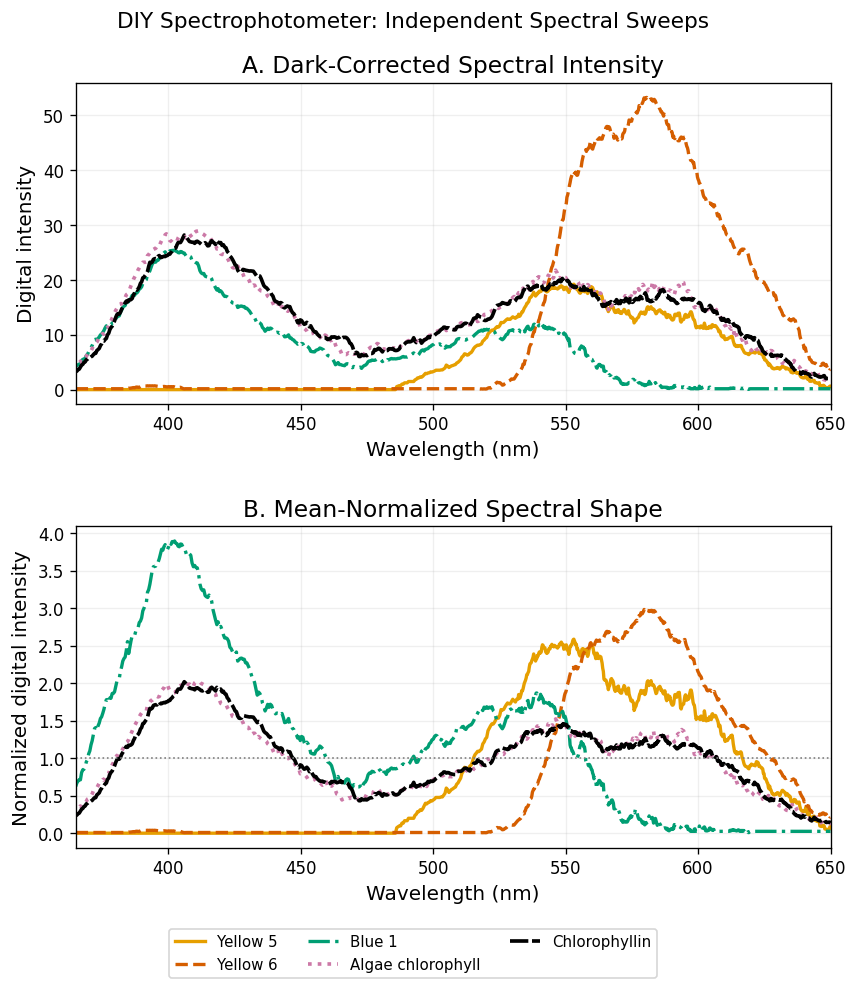

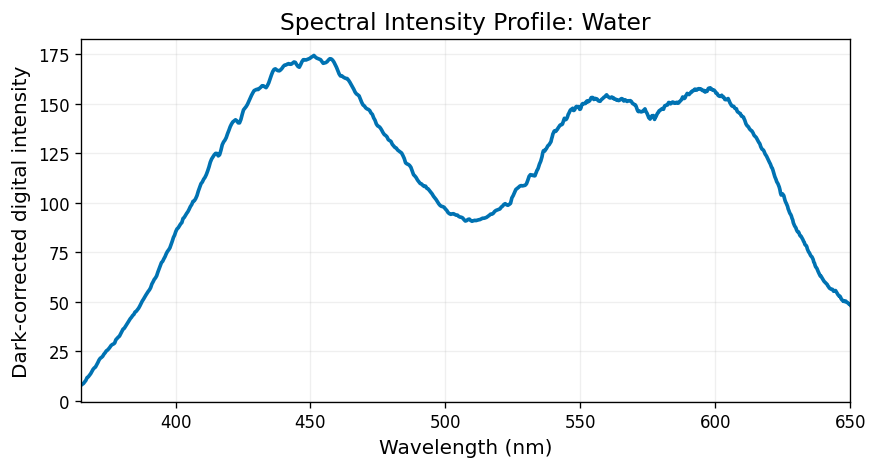

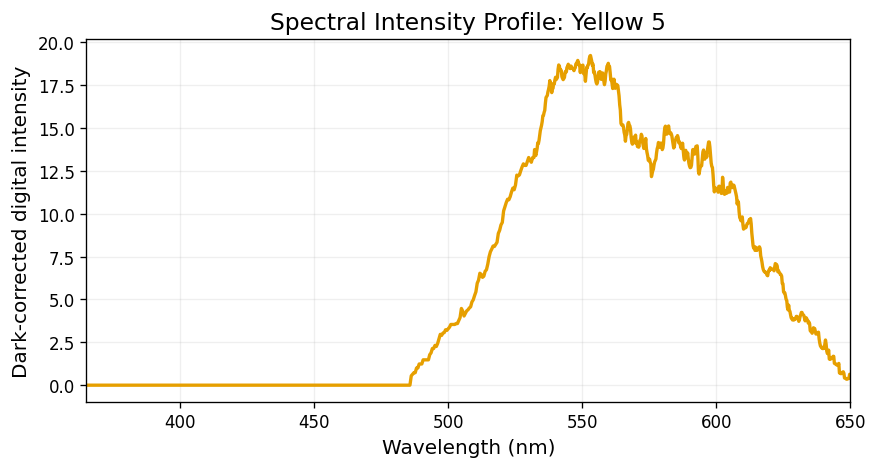

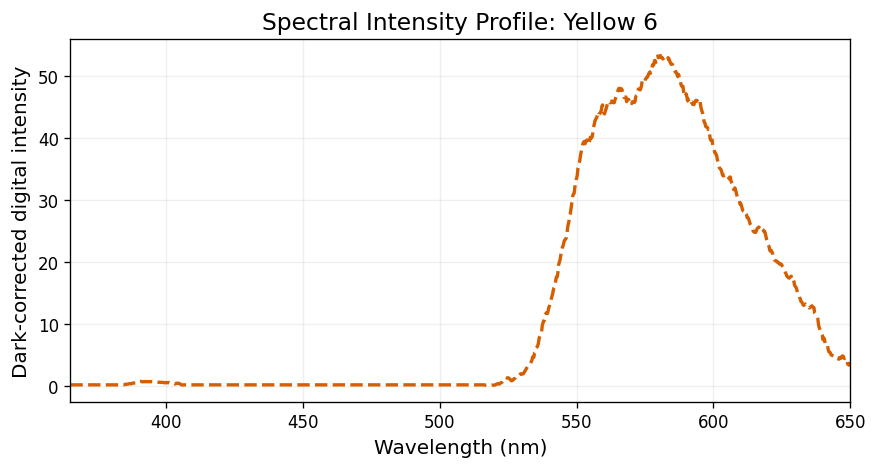

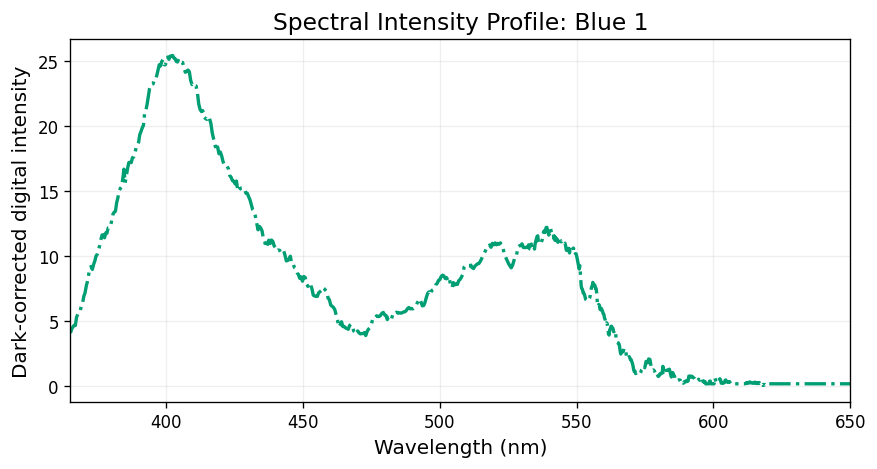

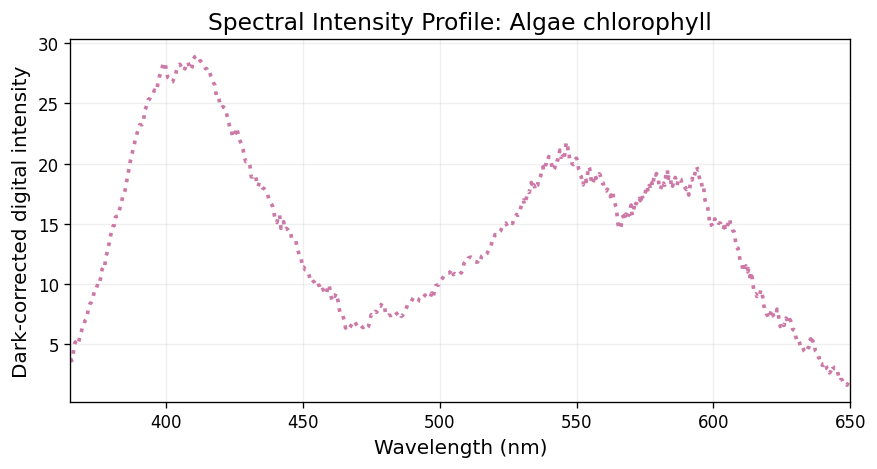

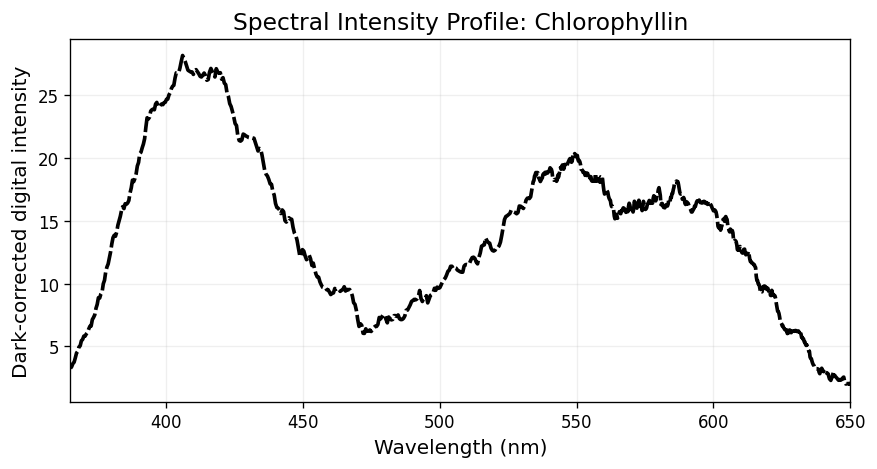


--- INDEPENDENT SPECTRAL SWEEP SUMMARY ---
Processed images: 6
Calibrated wavelength positions: 847


,Substance,Valid_spectral_positions,Mean_intensity,Minimum_intensity,Maximum_intensity,Near_saturation_RGB_percent
0,Water,847,120.4220,7.7773,174.4184,8.7868
1,Yellow 5,847,7.4314,0.0000,19.2245,0.0000
2,Yellow 6,847,17.8307,0.1077,53.2724,0.0000
3,Blue 1,847,6.5271,0.0544,25.4336,0.0000
4,Algae chlorophyll,847,14.2908,1.6027,28.9645,0.0000
5,Chlorophyllin,847,13.9507,1.9071,28.1795,0.0000



--- INTERPRETATION NOTES ---
Water is included as a reference intensity profile.
Digital intensity profiles are not absorbance spectra.
Mean normalization removes overall brightness differences but does not correct camera exposure or spectral response.
Different sample solvents and acquisition conditions may affect the observed spectral profiles.
Absorption-band identification requires appropriate sample-matched references.

Qualitative spectral comparison completed.


In [10]:
# ============================================================
# 10. QUALITATIVE SPECTRAL COMPARISON OF CHROMOPHORIC SAMPLES
# ============================================================

# Compare independent spectral sweeps of different chromophoric samples using dark-corrected digital intensity and
# mean-normalized spectral shape.

spectra = {}
spectral_summary = []

# Use only wavelengths supported by the DIY calibration.
valid_sweep_pixels = np.flatnonzero(
    np.isfinite(wavelengths)
    & (wavelengths >= CAL_MIN)
    & (wavelengths <= CAL_MAX)
)

if len(valid_sweep_pixels) < 20:
    raise ValueError(
        'Insufficient calibrated wavelength positions.'
    )

# ------------------------------------------------------------
# PROCESS INDEPENDENT SPECTRAL SWEEPS
# ------------------------------------------------------------

for name, filename in DYES.items():

    if name == 'Hibiscus extract':
        continue

    # Apply the same dark correction to all images.
    image = subtract_dark(filename)

    # Extract the spectral profile
    intensity = spectrum_profile(image)

    valid_intensity = intensity[valid_sweep_pixels]

    if not np.all(np.isfinite(valid_intensity)):
        raise ValueError(
            f'Invalid intensity values for {name}.'
        )

    mean_intensity = float(np.mean(valid_intensity))

    if mean_intensity <= 0:
        raise ValueError(
            f'Non-positive mean spectral intensity for {name}.'
        )

    # Normalize each profile by its own mean intensity.
    normalized_intensity = intensity / mean_intensity

    # Preserve the original dictionary structure.
    spectra[name] = {
        'wavelengths': wavelengths.copy(),
        'intensity': intensity,
        'rgb': image,
        'normalized_intensity': normalized_intensity
    }

    # Inspect the original JPEG image for near-saturation.
    original_image = load_rgb(filename)

    center_row = original_image.shape[0] // 2
    start_row = max(0, center_row - 5)
    end_row = min(original_image.shape[0], center_row + 6)

    original_region = original_image[
        start_row:end_row,
        :,
        :
    ]

    calibrated_region = original_region[
        :,
        valid_sweep_pixels,
        :
    ]

    saturation_percent = float(
        100 * np.mean(calibrated_region >= 250)
    )

    # Export the individual spectral profile.
    table = pd.DataFrame({
        'Pixel': valid_sweep_pixels,
        'Wavelength_nm': wavelengths[valid_sweep_pixels],
        'Dark_corrected_intensity': valid_intensity,
        'Mean_normalized_intensity':
            normalized_intensity[valid_sweep_pixels]
    })

    table.to_csv(
        OUTPUT_DIR / f'Sweep_{name.replace(" ", "_")}.csv',
        index=False
    )

    spectral_summary.append({
        'Substance': name,
        'Valid_spectral_positions': len(valid_sweep_pixels),
        'Mean_intensity': mean_intensity,
        'Minimum_intensity': float(np.min(valid_intensity)),
        'Maximum_intensity': float(np.max(valid_intensity)),
        'Near_saturation_RGB_percent': saturation_percent
    })


# ============================================================
# VISUALIZATION OF INDEPENDENT SPECTRAL SWEEPS
# ============================================================

plot_samples = [
    'Yellow 5',
    'Yellow 6',
    'Blue 1',
    'Algae chlorophyll',
    'Chlorophyllin'
]

for name in plot_samples:
    if name not in spectra:
        raise ValueError(f'Missing spectral profile: {name}')

# ------------------------------------------------------------
# FIGURE 10A: COMBINED SPECTRAL COMPARISON
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1,
    figsize=(7.4, 8.5)
)

fig.subplots_adjust(
    left=0.12,
    right=0.97,
    top=0.91,
    bottom=0.16,
    hspace=0.38
)

for name in plot_samples:

    entry = spectra[name]
    style = SAMPLE_STYLE[name]

    # Panel A: original dark-corrected intensity.
    axes[0].plot(
        entry['wavelengths'],
        entry['intensity'],
        label=name,
        **style
    )

    # Panel B: spectral shape normalized by mean intensity.
    axes[1].plot(
        entry['wavelengths'],
        entry['normalized_intensity'],
        label=name,
        **style
    )

# ------------------------------------------------------------
# FORMAT PANEL A
# ------------------------------------------------------------

axes[0].set_title(
    'A. Dark-Corrected Spectral Intensity'
)

axes[0].set_xlabel('Wavelength (nm)')
axes[0].set_ylabel('Digital intensity')

axes[0].set_xlim(
    CALIBRATED_MIN,
    CALIBRATED_MAX
)

axes[0].grid(True, alpha=0.20)

# ------------------------------------------------------------
# FORMAT PANEL B
# ------------------------------------------------------------

axes[1].set_title(
    'B. Mean-Normalized Spectral Shape'
)

axes[1].set_xlabel('Wavelength (nm)')
axes[1].set_ylabel('Normalized digital intensity')

axes[1].set_xlim(
    CALIBRATED_MIN,
    CALIBRATED_MAX
)

axes[1].axhline(
    1,
    color=CB_PALETTE['gray'],
    linestyle=':',
    linewidth=1
)

axes[1].grid(True, alpha=0.20)

# ------------------------------------------------------------
# SHARED LEGEND
# ------------------------------------------------------------

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.025),
    ncol=3,
    fontsize=9,
    frameon=True
)

fig.suptitle(
    'DIY Spectrophotometer: Independent Spectral Sweeps',
    fontsize=13
)

plt.savefig(
    OUTPUT_DIR / '05_independent_spectral_profiles.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ------------------------------------------------------------
# FIGURE 10B: INDIVIDUAL SPECTRAL PROFILES
# ------------------------------------------------------------

for name, entry in spectra.items():

    fig, ax = plt.subplots(
        figsize=(7.2, 3.8),
        constrained_layout=True
    )

    style = SAMPLE_STYLE[name]

    ax.plot(
        entry['wavelengths'],
        entry['intensity'],
        **style
    )

    ax.set_title(
        f'Spectral Intensity Profile: {name}'
    )

    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('Dark-corrected digital intensity')

    ax.set_xlim(
        CALIBRATED_MIN,
        CALIBRATED_MAX
    )

    ax.grid(True, alpha=0.20)

    plt.savefig(
        OUTPUT_DIR / f'Sweep_{name.replace(" ", "_")}.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()


# ------------------------------------------------------------
# EXPORT AND DISPLAY THE SPECTRAL SUMMARY
# ------------------------------------------------------------

df_dye_intensity_summary = pd.DataFrame(spectral_summary)

df_dye_intensity_summary.to_csv(
    OUTPUT_DIR / 'Qualitative_Spectral_Summary.csv',
    index=False
)

print('\n--- INDEPENDENT SPECTRAL SWEEP SUMMARY ---')

print(f'Processed images: {len(spectra)}')

print(
    f'Calibrated wavelength positions: '
    f'{len(valid_sweep_pixels)}'
)

display(df_dye_intensity_summary.round(4))

print('\n--- INTERPRETATION NOTES ---')

print(
    'Water is included as a reference intensity profile.'
)

print(
    'Digital intensity profiles are not absorbance spectra.'
)

print(
    'Mean normalization removes overall brightness differences but does not correct camera exposure or spectral response.'
)

print(
    'Different sample solvents and acquisition conditions may affect the observed spectral profiles.'
)

print(
    'Absorption-band identification requires appropriate sample-matched references.'
)

print('\nQualitative spectral comparison completed.')


--- COMMERCIAL CSV IMPORT ---
CSV files found: 7
IMPORTED: Yellow 5 (401 spectral points)
IMPORTED: Yellow 6 (401 spectral points)
IMPORTED: Blue 1 (401 spectral points)
EXCLUDED (preliminary ethanol test): Barrido Clorofilina etanol.csv
IMPORTED: Chlorophyllin (401 spectral points)
SKIPPED: Barrido blanco agua.csv (no matching study sample)
IMPORTED: Algae chlorophyll (401 spectral points)

Commercial CSV import completed.


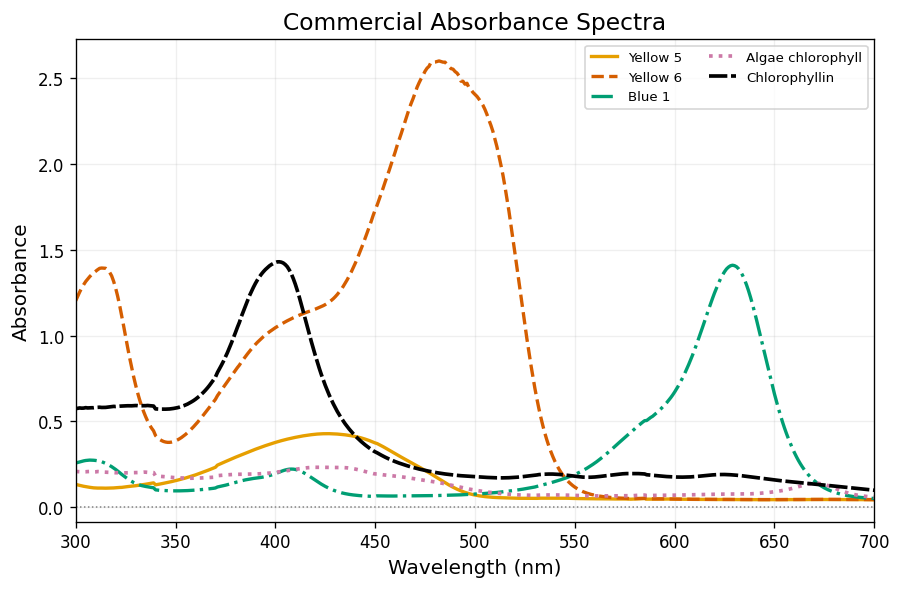


--- COMMERCIAL SPECTRAL SUMMARY ---


,Substance,Filename,Data_points,Minimum_wavelength_nm,Maximum_wavelength_nm,Maximum_absorbance,Wavelength_at_maximum_nm
0,Yellow 5,Barrido Amarillo 5.csv,401,300.0,700.0,0.4292,426.0
1,Yellow 6,Barrido Amarillo 6.csv,401,300.0,700.0,2.5970,482.0
2,Blue 1,Barrido Azul 1.csv,401,300.0,700.0,1.4089,629.0
3,Chlorophyllin,Barrido Clorofilina.csv,401,300.0,700.0,1.4287,402.0
4,Algae chlorophyll,Barrido clorofila algas.csv,401,300.0,700.0,0.2337,421.0



Commercial spectra successfully matched: 5
Commercial wavelengths are preserved as recorded.
DIY and commercial absorbance have not been compared or normalized.

Commercial spectral import completed.


In [11]:
# ============================================================
# 11. COMMERCIAL SPECTRAL DATA IMPORT AND INSPECTION
# ============================================================

import re
import unicodedata

# Import Comercial spectral CSV files.
# The commercial data contain wavelength, absorbance, and percentage transmittance.

commercial_spectra = {}
commercial_import_summary = []

# Optional manual assignments for filenames that cannot be identified automatically.
# Example:'My_Sample_File.csv': 'Blue 1'

COMMERCIAL_FILE_MAP = {
    'Barrido Clorofilina.csv': 'Chlorophyllin'
}

# ------------------------------------------------------------
# IDENTIFY SAMPLE NAMES FROM CSV FILENAMES
# ------------------------------------------------------------

def identify_commercial_sample(filename):

    name = unicodedata.normalize(
        'NFKD', filename
    ).encode(
        'ascii', 'ignore'
    ).decode('ascii').lower()

    name = re.sub(r'[^a-z0-9]+', ' ', name)
    name = ' '.join(name.split())

    if 'jamaica' in name or 'hibiscus' in name:
        return None

    if 'clorofilina' in name or 'chlorophyllin' in name:
        return 'Chlorophyllin'

    if 'clorofila' in name or 'chlorophyll' in name:
        return 'Algae chlorophyll'

    if 'amarillo 5' in name or 'yellow 5' in name:
        return 'Yellow 5'

    if 'amarillo 6' in name or 'yellow 6' in name:
        return 'Yellow 6'

    if 'azul 1' in name or 'blue 1' in name:
        return 'Blue 1'

    return None


# ------------------------------------------------------------
# READ THE COMMERCIAL SPECTRAL CSV FORMAT
# ------------------------------------------------------------

def read_commercial_csv(path):

    # The COMMERCIAL export contains instrument metadata before the spectral data header.

    text = None
    encoding_used = None

    for encoding in ('utf-8-sig', 'cp1252', 'latin-1'):
        try:
            text = path.read_text(encoding=encoding)
            encoding_used = encoding
            break
        except UnicodeDecodeError:
            continue

    if text is None:
        raise ValueError(
            f'Unable to decode commercial file: {path.name}'
        )

    lines = text.splitlines()
    header_line = None

    for i, line in enumerate(lines):

        normalized_header = re.sub(
            r'\s+', '', line.lower()
        )

        if normalized_header.startswith(
            'wl(nm),abs,t%'
        ):
            header_line = i
            break

    if header_line is None:
        raise ValueError(
            f'Commercial spectral header not found in {path.name}. '
            'Expected: WL(nm), Abs, T%'
        )

    table = pd.read_csv(
        path,
        skiprows=header_line,
        encoding=encoding_used
    )

    if table.shape[1] < 3:
        raise ValueError(
            f'Insufficient spectral columns: {path.name}'
        )

    # Preserve the original numerical data.
    table = table.iloc[:, :3].copy()

    table.columns = [
        'Wavelength_nm',
        'Commercial_absorbance',
        'Commercial_transmittance_percent'
    ]

    for column in table.columns:
        table[column] = pd.to_numeric(
            table[column],
            errors='raise'
        )

    if not np.all(
        np.isfinite(table.to_numpy(dtype=float))
    ):
        raise ValueError(
            f'Non-finite spectral values in {path.name}'
        )

    if table['Wavelength_nm'].duplicated().any():
        raise ValueError(
            f'Duplicate wavelength values in {path.name}'
        )

    table = table.sort_values(
        'Wavelength_nm'
    ).reset_index(drop=True)

    return table


# ------------------------------------------------------------
# IMPORT ALL AVAILABLE COMMERCIAL SPECTRA
# ------------------------------------------------------------

commercial_csv = sorted(
    COMMERCIAL_DIR.glob('*.csv')
)

print('\n--- COMMERCIAL CSV IMPORT ---')
print(f'CSV files found: {len(commercial_csv)}')

for path in commercial_csv:

    # Exclude the preliminary chlorophyllin ethanol test.
    if path.name == 'Barrido Clorofilina etanol.csv':
        print(
            f'EXCLUDED (preliminary ethanol test): {path.name}'
        )
        continue

    # Manual filename assignments take priority.
    if path.name in COMMERCIAL_FILE_MAP:
        sample_name = COMMERCIAL_FILE_MAP[path.name]
    else:
        sample_name = identify_commercial_sample(
            path.name
        )

    # Exclude unrecognized samples.
    if sample_name not in [
        'Yellow 5',
        'Yellow 6',
        'Blue 1',
        'Algae chlorophyll',
        'Chlorophyllin'
    ]:
        print(
            f'SKIPPED: {path.name} '
            '(no matching study sample)'
        )
        continue

    # Prevent unintended duplicate sample assignments.
    if sample_name in commercial_spectra:
        print(
            f'WARNING: Duplicate commercial spectrum '
            f'for {sample_name}: {path.name}. '
            'The file was not added.'
        )
        continue

    # Read the commercial spectrophotometer CSV.
    table = read_commercial_csv(path)

    # Store the commercial spectrum.
    commercial_spectra[sample_name] = table

    # Identify the maximum recorded absorbance.
    max_index = table[
        'Commercial_absorbance'
    ].idxmax()

    # Store the spectral summary.
    commercial_import_summary.append({
        'Substance': sample_name,
        'Filename': path.name,
        'Data_points': len(table),
        'Minimum_wavelength_nm':
            table['Wavelength_nm'].min(),
        'Maximum_wavelength_nm':
            table['Wavelength_nm'].max(),
        'Maximum_absorbance':
            table.loc[
                max_index,
                'Commercial_absorbance'
            ],
        'Wavelength_at_maximum_nm':
            table.loc[
                max_index,
                'Wavelength_nm'
            ]
    })

    # Export the commercial spectrum.
    table.to_csv(
        OUTPUT_DIR /
        f'Commercial_{sample_name.replace(" ", "_")}.csv',
        index=False
    )

    print(
        f'IMPORTED: {sample_name} '
        f'({len(table)} spectral points)'
    )

print('\nCommercial CSV import completed.')



# ------------------------------------------------------------
# COMMERCIAL ABSORBANCE PLOT
# ------------------------------------------------------------

commercial_order = [
    'Yellow 5',
    'Yellow 6',
    'Blue 1',
    'Algae chlorophyll',
    'Chlorophyllin'
]

fig, ax = plt.subplots(
    figsize=(7.4, 4.8),
    constrained_layout=True
)

for name in commercial_order:

    if name not in commercial_spectra:
        raise ValueError(
            f'Missing commercial spectrum: {name}'
        )

    table = commercial_spectra[name]

    ax.plot(
        table['Wavelength_nm'],
        table['Commercial_absorbance'],
        label=name,
        **SAMPLE_STYLE[name]
    )

# ------------------------------------------------------------
# FIGURE FORMATTING
# ------------------------------------------------------------

ax.set_title(
    'Commercial Absorbance Spectra'
)

ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Absorbance')

# Preserve the complete commercial measurement range.
ax.set_xlim(300, 700)

ax.axhline(
    0,
    color=CB_PALETTE['gray'],
    linestyle=':',
    linewidth=0.9
)

ax.grid(True, alpha=0.20)

ax.legend(
    loc='upper right',
    ncol=2,
    fontsize=8,
    frameon=True
)

# ------------------------------------------------------------
# EXPORT THE FIGURE
# ------------------------------------------------------------

plt.savefig(
    OUTPUT_DIR / '06_commercial_absorbance_spectra.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# EXPORT AND DISPLAY THE IMPORT SUMMARY
# ------------------------------------------------------------

df_commercial_import_summary = pd.DataFrame(
    commercial_import_summary
)

df_commercial_import_summary.to_csv(
    OUTPUT_DIR / 'Commercial_Spectral_Import_Summary.csv',
    index=False
)

print('\n--- COMMERCIAL SPECTRAL SUMMARY ---')

display(df_commercial_import_summary)

print(
    '\nCommercial spectra successfully matched:',
    len(commercial_spectra)
)

print(
    'Commercial wavelengths are preserved as recorded.'
)

print(
    'DIY and commercial absorbance have not been compared or normalized.'
)

print('\nCommercial spectral import completed.')


--- WATER REFERENCE QUALITY CONTROL ---
Near-saturated RGB values: 8.79%
Apparent absorbance may be affected by camera saturation and nonlinear response.


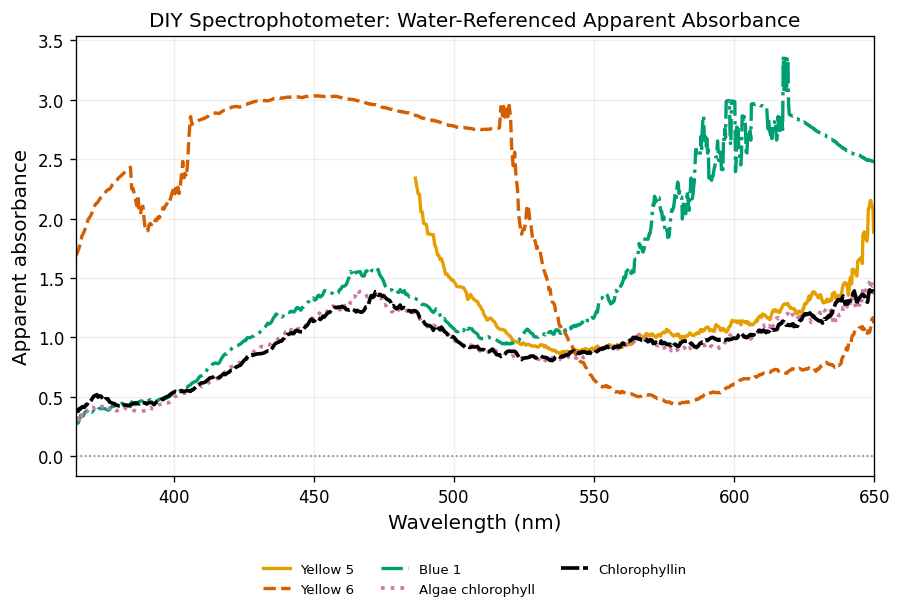

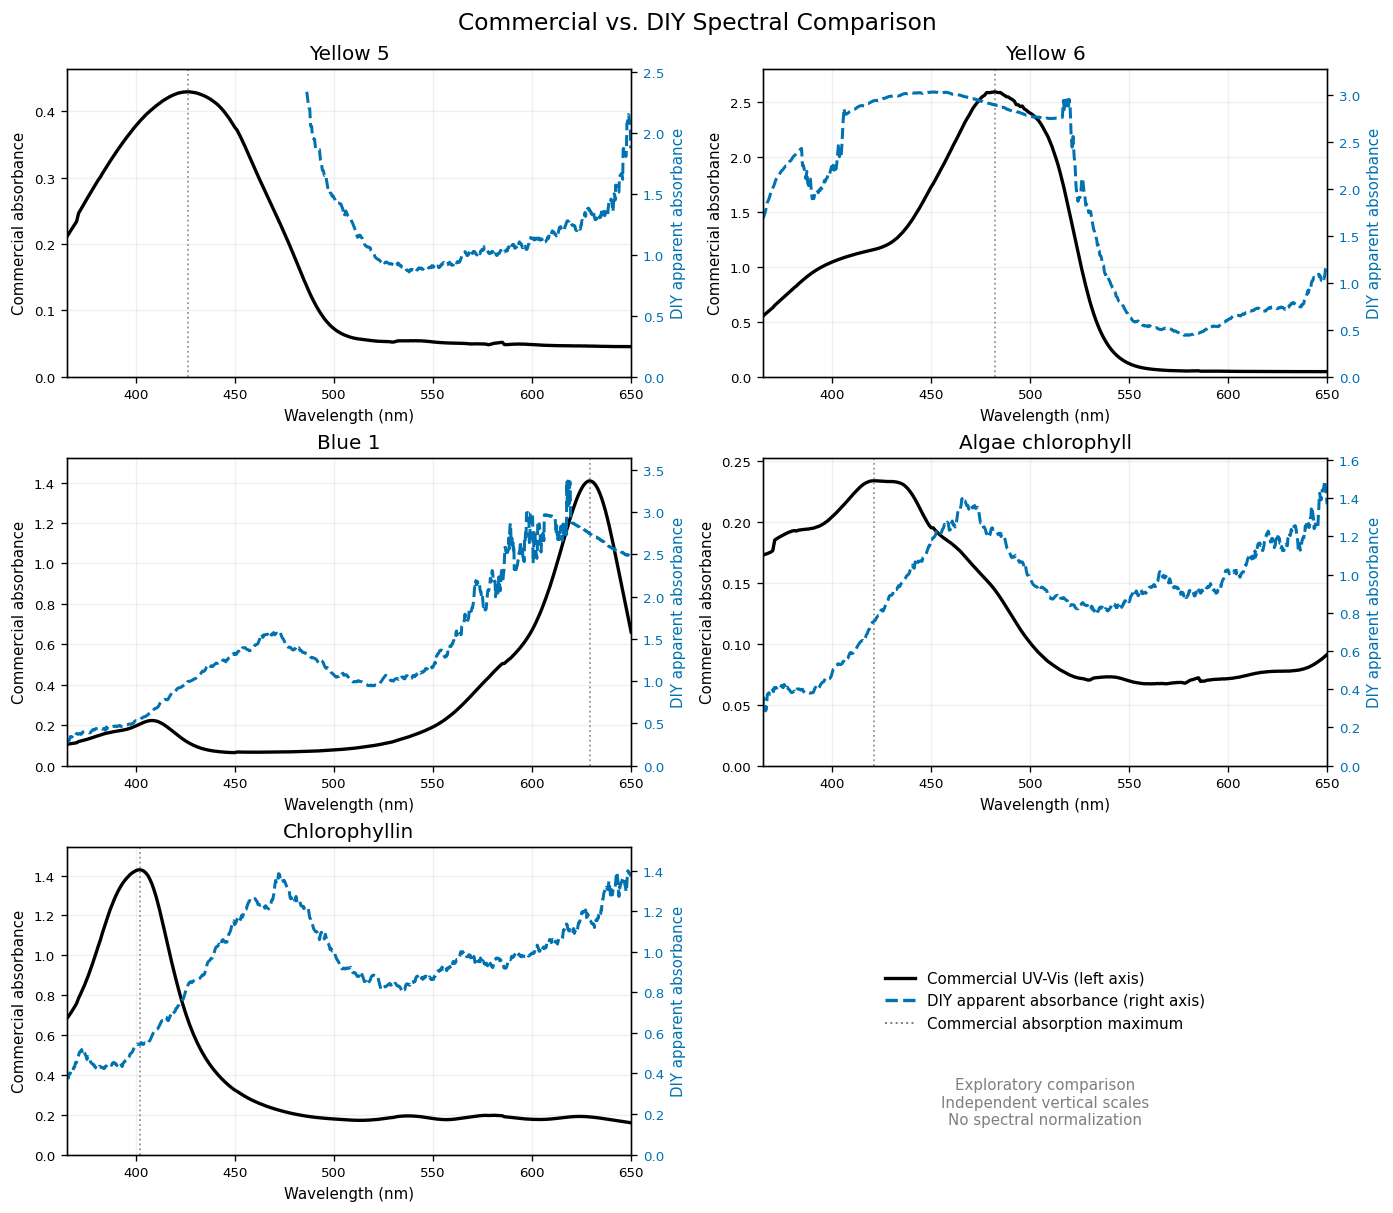


--- DIY APPARENT ABSORBANCE QUALITY CONTROL ---


,Substance,Reference,Calibrated_positions,Valid_absorbance_positions,Valid_absorbance_percent,Negative_absorbance_percent,Sample_RGB_near_saturation_percent,Valid_positions_with_saturated_reference_percent
0,Yellow 5,Water,847,592,69.8937,0.0,0.0,22.6351
1,Yellow 6,Water,847,847,100.0000,0.0,0.0,38.2527
2,Blue 1,Water,847,847,100.0000,0.0,0.0,38.2527
3,Algae chlorophyll,Water,847,847,100.0000,0.0,0.0,38.2527
4,Chlorophyllin,Water,847,847,100.0000,0.0,0.0,38.2527



--- ANALYSIS SUMMARY ---
Chromophoric samples analyzed: 5
Reference used for all independent DIY sweeps: Water
Comparison wavelength interval: 365–650 nm
The original commercial spectra remain available over their full 300–700 nm measurement range.

--- INTERPRETATION NOTES ---
DIY values represent apparent absorbance derived from digital JPEG intensity profiles.
Commercial and DIY spectra were not shifted, normalized, baseline-corrected, or forced to match.
Negative apparent absorbance values were retained.
Invalid intensity ratios were left undefined (NaN).
Differences in exposure, illumination, optical geometry, and camera processing may affect the DIY results.
The commercial absorbance and DIY apparent absorbance have not been demonstrated to be photometrically equivalent.

Water-referenced spectral comparison completed.


In [12]:
# ============================================================================
# 12. WATER-REFERENCED APPARENT ABSORBANCE AND COMMERCIAL SPECTRAL COMPARISON
# ============================================================================

# Calculate water-referenced apparent absorbance for five independent DIY spectral sweeps and compare their profiles
# with commercial absorbance spectra.
#
# All five DIY sweeps were acquired using water as solvent.
#
# No spectral shifting, normalization, baseline subtraction, or artificial peak alignment is performed.

# ------------------------------------------------------------
# DEFINE MATCHED SOLVENT REFERENCES
# ------------------------------------------------------------

REFERENCES = {
    'Yellow 5': 'Water',
    'Yellow 6': 'Water',
    'Blue 1': 'Water',
    'Algae chlorophyll': 'Water',
    'Chlorophyllin': 'Water'
}

samples_to_compare = list(REFERENCES.keys())

# Verify that all required data are available.
if 'Water' not in spectra:
    raise ValueError(
        'The water reference spectrum is missing.'
    )

for name in samples_to_compare:

    if name not in spectra:
        raise ValueError(
            f'DIY spectrum not found: {name}'
        )

    if name not in commercial_spectra:
        raise ValueError(
            f'Commercial spectrum not found: {name}'
        )

# Use the measured dark-corrected water spectrum.
water_reference_intensity = spectra['Water']['intensity']

# Restrict comparison to experimentally assigned wavelengths.
common_wavelength_mask = (
    np.isfinite(wavelengths)
    & (wavelengths >= CALIBRATED_MIN)
    & (wavelengths <= CALIBRATED_MAX)
)

if not np.any(common_wavelength_mask):
    raise ValueError(
        'No valid calibrated wavelength positions.'
    )

# ------------------------------------------------------------
# CHECK THE ORIGINAL WATER REFERENCE FOR SATURATION
# ------------------------------------------------------------

water_original = load_rgb(DYES['Water'])

center_row = water_original.shape[0] // 2
start_row = max(0, center_row - 5)
end_row = min(water_original.shape[0], center_row + 6)

water_original_region = water_original[
    start_row:end_row, :, :
]

# Flag wavelength positions where at least one RGB pixel in the extraction region is near saturation.
water_saturated_pixels = np.any(
    water_original_region >= 250,
    axis=(0, 2)
)

water_saturation_percent = (
    100 * np.mean(
        water_original_region[
            :, common_wavelength_mask, :
        ] >= 250
    )
)

print('\n--- WATER REFERENCE QUALITY CONTROL ---')

print(
    f'Near-saturated RGB values: '
    f'{water_saturation_percent:.2f}%'
)

if water_saturation_percent > 0:
    print(
        'WARNING: Near-saturation was detected '
        'in the original water reference image.'
    )
    print(
        'Apparent absorbance may be affected '
        'by camera saturation and nonlinear response.'
    )

# ------------------------------------------------------------
# CALCULATE DIY APPARENT ABSORBANCE
# ------------------------------------------------------------

sweep_tables = {}
summary = []

for name in samples_to_compare:

    # Both profiles have already been corrected using the same dark-reference image.
    sample_intensity = spectra[name]['intensity']

    reference_intensity = water_reference_intensity

    # Calculate apparent transmittance and absorbance.
    T, A = calculate_absorbance(
        sample_intensity,
        reference_intensity,
        wavelengths
    )

    valid = (
        common_wavelength_mask
        & np.isfinite(T)
        & np.isfinite(A)
    )

    negative = valid & (A < 0)

    # Load the original image for saturation diagnostics.
    original_image = load_rgb(DYES[name])

    sample_original_region = original_image[
        start_row:end_row, :, :
    ]

    sample_saturation_percent = (
        100 * np.mean(
            sample_original_region[
                :, common_wavelength_mask, :
            ] >= 250
        )
    )

    # Preserve all data, including negative values.
    # Undefined values remain NaN.
    table = pd.DataFrame({
        'Pixel': pixels,
        'Wavelength_nm': wavelengths,
        'Sample_intensity': sample_intensity,
        'Reference_intensity': reference_intensity,
        'Transmittance': T,
        'Transmittance_percent': 100 * T,
        'Absorbance': A,
        'Within_calibration': common_wavelength_mask,
        'Valid_absorbance': valid,
        'Negative_absorbance': negative,
        'Reference_near_saturation':
            water_saturated_pixels
    })

    sweep_tables[name] = table

    table.to_csv(
        OUTPUT_DIR /
        f'Dye_{name.replace(" ", "_")}.csv',
        index=False
    )

    n_valid = int(np.count_nonzero(valid))
    n_total = int(np.count_nonzero(common_wavelength_mask))
    n_negative = int(np.count_nonzero(negative))

    valid_percent = (
        100 * n_valid / n_total
        if n_total > 0 else np.nan
    )

    negative_percent = (
        100 * n_negative / n_valid
        if n_valid > 0 else np.nan
    )

    # Count valid absorbance positions affected by near-saturation of the reference.
    saturated_reference_valid_percent = (
        100 * np.count_nonzero(
            valid & water_saturated_pixels
        ) / n_valid
        if n_valid > 0 else np.nan
    )

    summary.append({
        'Substance': name,
        'Reference': 'Water',
        'Calibrated_positions': n_total,
        'Valid_absorbance_positions': n_valid,
        'Valid_absorbance_percent': valid_percent,
        'Negative_absorbance_percent': negative_percent,
        'Sample_RGB_near_saturation_percent':
            sample_saturation_percent,
        'Valid_positions_with_saturated_reference_percent':
            saturated_reference_valid_percent
    })

# ------------------------------------------------------------
# EXPORT THE DIY QUALITY-CONTROL SUMMARY
# ------------------------------------------------------------

df_dye_summary = pd.DataFrame(summary)

df_dye_summary.to_csv(
    OUTPUT_DIR / 'DIY_Apparent_Absorbance_Quality_Control.csv',
    index=False
)


# ------------------------------------------------------------
# FIGURE 12A: ALL DIY APPARENT ABSORBANCE SPECTRA
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(7.4, 5.0),
    constrained_layout=True
)

plot_order = [
    'Yellow 5',
    'Yellow 6',
    'Blue 1',
    'Algae chlorophyll',
    'Chlorophyllin'
]

for name in plot_order:

    if name not in sweep_tables:
        raise ValueError(
            f'Missing DIY apparent absorbance data: {name}'
        )

    table = sweep_tables[name]

    ax.plot(
        table['Wavelength_nm'],
        table['Absorbance'],
        label=name,
        **SAMPLE_STYLE[name]
    )

# ------------------------------------------------------------
# FIGURE FORMATTING
# ------------------------------------------------------------

ax.axhline(
    0,
    color=CB_PALETTE['gray'],
    linestyle=':',
    linewidth=1.0
)

ax.set_xlim(
    CALIBRATED_MIN,
    CALIBRATED_MAX
)

ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('Apparent absorbance')

ax.set_title(
    'DIY Spectrophotometer: Water-Referenced Apparent Absorbance',
    fontsize=12
)

ax.grid(True, alpha=0.20)

ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.17),
    ncol=3,
    fontsize=8,
    frameon=False
)

# ------------------------------------------------------------
# EXPORT THE FIGURE
# ------------------------------------------------------------

plt.savefig(
    OUTPUT_DIR / '07_DIY_Apparent_Absorbance_Spectra.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# FIGURE 12B: COMMERCIAL VS DIY SPECTRAL OVERLAY
# ------------------------------------------------------------

from matplotlib.lines import Line2D

fig, axes = plt.subplots(
    3, 2,
    figsize=(11.5, 10),
    constrained_layout=True
)

axes = axes.ravel()

for ax, name in zip(axes, samples_to_compare):

    commercial_table = commercial_spectra[name]
    diy_table = sweep_tables[name]

    # --------------------------------------------------------
    # COMMERCIAL DATA
    # --------------------------------------------------------

    x_com = commercial_table[
        'Wavelength_nm'
    ].to_numpy(dtype=float)

    y_com = commercial_table[
        'Commercial_absorbance'
    ].to_numpy(dtype=float)

    commercial_valid = (
        np.isfinite(x_com)
        & np.isfinite(y_com)
        & (x_com >= CALIBRATED_MIN)
        & (x_com <= CALIBRATED_MAX)
    )

    x_com = x_com[commercial_valid]
    y_com = y_com[commercial_valid]

    # --------------------------------------------------------
    # DIY DATA
    # --------------------------------------------------------

    x_diy = diy_table[
        'Wavelength_nm'
    ].to_numpy(dtype=float)

    y_diy = diy_table[
        'Absorbance'
    ].to_numpy(dtype=float)

    diy_range = (
        np.isfinite(x_diy)
        & (x_diy >= CALIBRATED_MIN)
        & (x_diy <= CALIBRATED_MAX)
    )


    x_diy = x_diy[diy_range]
    y_diy = y_diy[diy_range]

    if len(x_com) == 0 or not np.any(np.isfinite(y_diy)):
        raise ValueError(
            f'Insufficient comparison data for {name}.'
        )

    # --------------------------------------------------------
    # LEFT AXIS: COMMERCIAL ABSORBANCE
    # --------------------------------------------------------

    ax.plot(
        x_com,
        y_com,
        color=CB_PALETTE['black'],
        linestyle='-',
        linewidth=2.0
    )

    ax.set_ylabel(
        'Commercial absorbance',
        fontsize=9
    )

    ax.set_ylim(
        min(0.0, float(np.min(y_com))),
        max(0.1, float(np.max(y_com)) * 1.08)
    )

    # --------------------------------------------------------
    # RIGHT AXIS: DIY APPARENT ABSORBANCE
    # --------------------------------------------------------

    ax2 = ax.twinx()

    ax2.plot(
        x_diy,
        y_diy,
        color=CB_PALETTE['blue'],
        linestyle='--',
        linewidth=1.8
    )

    ax2.set_ylabel(
        'DIY apparent absorbance',
        color=CB_PALETTE['blue'],
        fontsize=9
    )

    ax2.tick_params(
        axis='y',
        labelcolor=CB_PALETTE['blue'],
        labelsize=8
    )

    valid_diy_values = y_diy[np.isfinite(y_diy)]

    ax2.set_ylim(
        min(0.0, float(np.min(valid_diy_values))),
        max(0.1, float(np.max(valid_diy_values)) * 1.08)
    )

    ax2.grid(False)

    # --------------------------------------------------------
    # COMMERCIAL ABSORPTION MAXIMUM
    # --------------------------------------------------------

    peak_nm = float(
        x_com[np.argmax(y_com)]
    )

    ax.axvline(
        peak_nm,
        color=CB_PALETTE['gray'],
        linestyle=':',
        linewidth=1.1,
        alpha=0.8
    )

    # --------------------------------------------------------
    # PANEL FORMATTING
    # --------------------------------------------------------

    ax.set_title(name, fontsize=12)

    ax.set_xlim(
        CALIBRATED_MIN,
        CALIBRATED_MAX
    )

    ax.set_xlabel(
        'Wavelength (nm)',
        fontsize=9
    )

    ax.tick_params(axis='both', labelsize=8)
    ax.grid(True, alpha=0.18)

# ------------------------------------------------------------
# COMMON LEGEND IN THE SIXTH PANEL
# ------------------------------------------------------------

axes[-1].axis('off')

legend_handles = [
    Line2D(
        [0], [0],
        color=CB_PALETTE['black'],
        linestyle='-',
        linewidth=2
    ),
    Line2D(
        [0], [0],
        color=CB_PALETTE['blue'],
        linestyle='--',
        linewidth=2
    ),
    Line2D(
        [0], [0],
        color=CB_PALETTE['gray'],
        linestyle=':',
        linewidth=1.2
    )
]

axes[-1].legend(
    handles=legend_handles,
    labels=[
        'Commercial UV-Vis (left axis)',
        'DIY apparent absorbance (right axis)',
        'Commercial absorption maximum'
    ],
    loc='center',
    fontsize=9,
    frameon=False
)

axes[-1].text(
    0.5,
    0.17,
    'Exploratory comparison\n'
    'Independent vertical scales\n'
    'No spectral normalization',
    transform=axes[-1].transAxes,
    ha='center',
    va='center',
    fontsize=9,
    color=CB_PALETTE['gray']
)

# ------------------------------------------------------------
# EXPORT
# ------------------------------------------------------------

fig.suptitle(
    'Commercial vs. DIY Spectral Comparison',
    fontsize=14
)

plt.savefig(
    OUTPUT_DIR / '08_Commercial_vs_DIY_Absorbance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# DISPLAY RESULTS AND WARNINGS
# ------------------------------------------------------------

print('\n--- DIY APPARENT ABSORBANCE QUALITY CONTROL ---')

display(df_dye_summary.round(4))

print('\n--- ANALYSIS SUMMARY ---')

print(f'Chromophoric samples analyzed: {len(samples_to_compare)}')

print(
    'Reference used for all independent DIY sweeps: Water'
)

print(
    f'Comparison wavelength interval: '
    f'{CALIBRATED_MIN:.0f}–{CALIBRATED_MAX:.0f} nm'
)

print(
    'The original commercial spectra remain available over their full 300–700 nm measurement range.'
)

print('\n--- INTERPRETATION NOTES ---')

print(
    'DIY values represent apparent absorbance derived from digital JPEG intensity profiles.'
)

print(
    'Commercial and DIY spectra were not shifted, normalized, baseline-corrected, or forced to match.'
)

print(
    'Negative apparent absorbance values were retained.'
)

print(
    'Invalid intensity ratios were left undefined (NaN).'
)

print(
    'Differences in exposure, illumination, optical geometry, and camera processing may affect the DIY results.'
)

print(
    'The commercial absorbance and DIY apparent absorbance have not been demonstrated to be photometrically equivalent.'
)

print(
    '\nWater-referenced spectral comparison completed.'
)

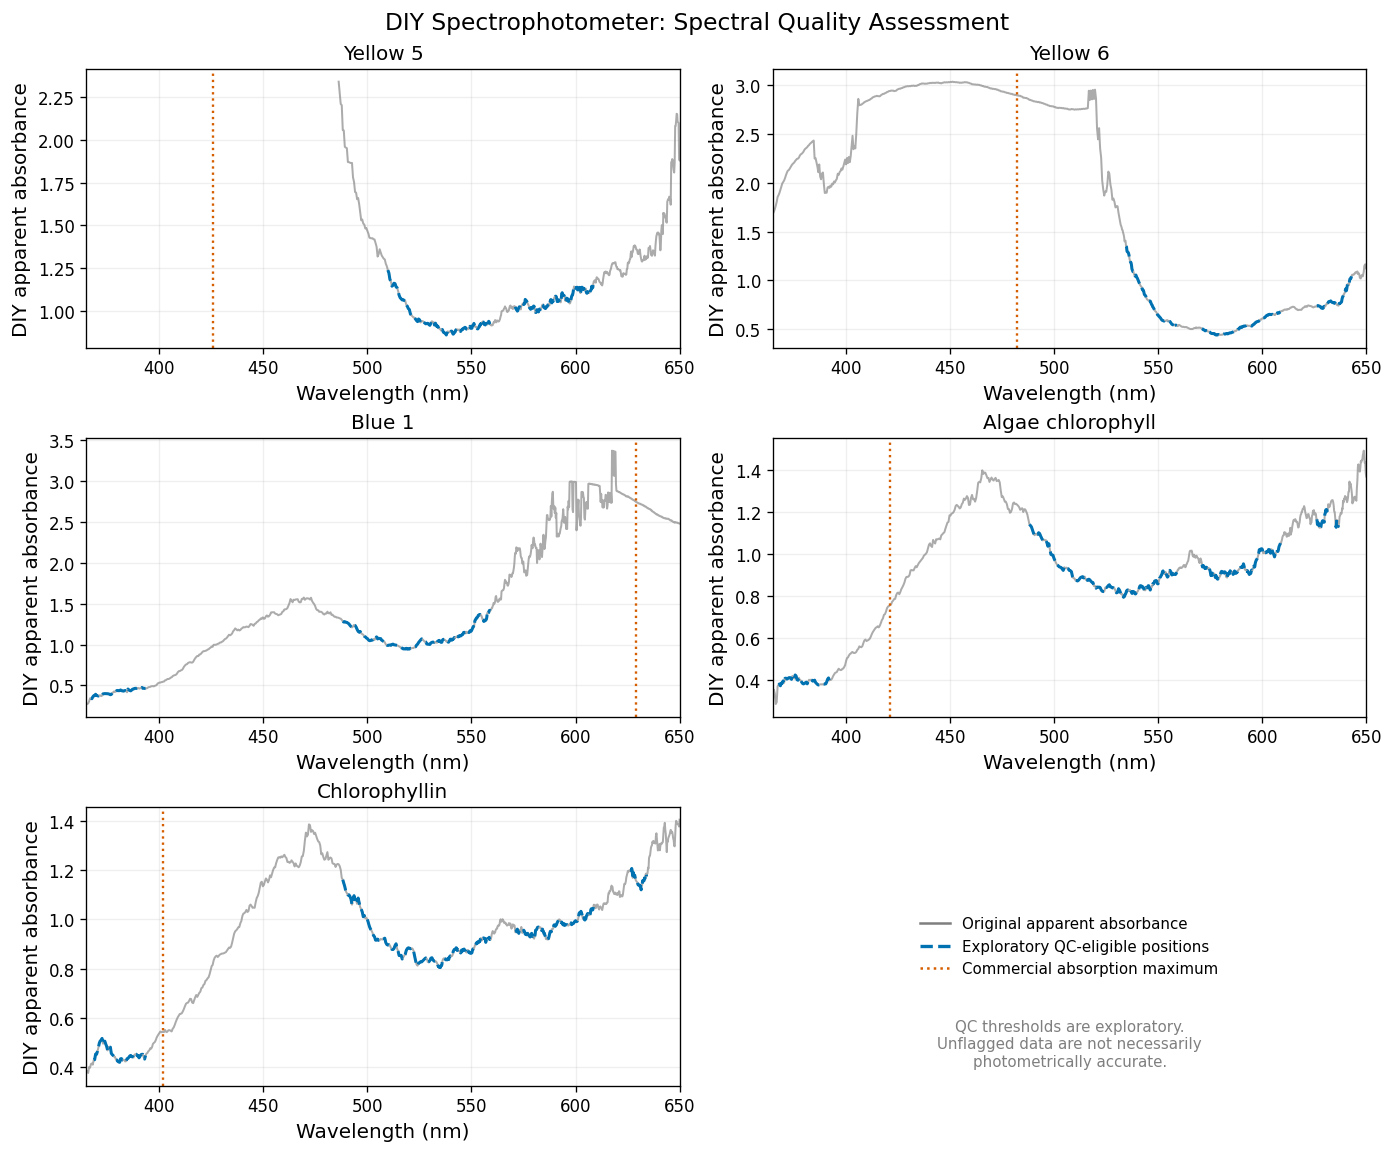


--- SPECTRAL QUALITY CONTROL SUMMARY ---


,Substance,Calibrated_positions,Mathematically_valid_positions,QC_eligible_positions,QC_eligible_percent,Minimum_eligible_wavelength_nm,Maximum_eligible_wavelength_nm,Commercial_maximum_nm,QC_data_near_commercial_maximum
0,Yellow 5,847,592,313,36.9540,509.8488,608.7711,426.0,False
1,Yellow 6,847,847,328,38.7249,534.6064,642.8916,482.0,False
2,Blue 1,847,847,262,30.9327,367.2222,559.0120,629.0,False
3,Algae chlorophyll,847,847,446,52.6564,366.7778,636.7309,421.0,False
4,Chlorophyllin,847,847,448,52.8926,368.5556,634.1245,402.0,False



--- SIGNAL FLOOR SENSITIVITY ---


,Substance,Signal_floor_digital_units,Eligible_positions,Eligible_percent
0,Yellow 5,2.0,409,48.2881
1,Yellow 5,5.0,313,36.9540
2,Yellow 5,10.0,290,34.2385
3,Yellow 6,2.0,371,43.8017
4,Yellow 6,5.0,328,38.7249
5,Yellow 6,10.0,295,34.8288
6,Blue 1,2.0,270,31.8772
7,Blue 1,5.0,262,30.9327
8,Blue 1,10.0,145,17.1192
9,Algae chlorophyll,2.0,511,60.3306



--- QUALITY-CONTROL CRITERIA ---
Near-saturation threshold: 250/255
Primary signal floor: 5.0 digital units
Signal floor thresholds are exploratory and are not validated detection limits.
Flagged values were not deleted or modified in the original spectral datasets.
Near-saturation indicates potential signal distortion, not proof that every flagged position is saturated.
Unflagged positions are not necessarily photometrically accurate.

Spectral quality assessment completed.


In [13]:
# ============================================================
# 13. SPECTRAL SIGNAL QUALITY ASSESSMENT
# ============================================================

# Identify potentially unreliable spectral positions caused by low digital intensity or near-saturation of JPEG pixels.
#
# These criteria are exploratory quality-control indicators.
# They do not correct exposure, validate absorbance, or establish instrument detection limits.
#
# Original spectra and numerical values remain unchanged.

QC_SATURATION_THRESHOLD = 250
QC_SIGNAL_FLOOR = 5.0
QC_SIGNAL_FLOOR_SENSITIVITY = [2.0, 5.0, 10.0]

QC_SAMPLES = [
    'Yellow 5',
    'Yellow 6',
    'Blue 1',
    'Algae chlorophyll',
    'Chlorophyllin'
]

# ------------------------------------------------------------
# DETECT NEAR-SATURATION IN THE ORIGINAL IMAGES
# ------------------------------------------------------------

def qc_near_saturation_mask(filename):

    original_image = load_rgb(filename)

    center_row = original_image.shape[0] // 2
    start_row = max(0, center_row - 5)
    end_row = min(original_image.shape[0], center_row + 6)

    region = original_image[start_row:end_row, :, :]

    # Mark a spectral position if at least one RGB value reaches the selected near-saturation threshold.
    return np.any(
        region >= QC_SATURATION_THRESHOLD,
        axis=(0, 2)
    )


qc_water_mask = qc_near_saturation_mask(
    DYES['Water']
)

# ------------------------------------------------------------
# EVALUATE SIGNAL QUALITY FOR EACH CHROMOPHORE
# ------------------------------------------------------------

qc_comparison_records = []
qc_sensitivity_records = []
qc_masked_spectra = {}

for name in QC_SAMPLES:

    table = sweep_tables[name]

    I = table['Sample_intensity'].to_numpy(dtype=float)
    I0 = table['Reference_intensity'].to_numpy(dtype=float)
    A = table['Absorbance'].to_numpy(dtype=float)

    sample_saturated = qc_near_saturation_mask(
        DYES[name]
    )

    # Preserve the mathematical validity criterion.
    mathematical_valid = (
        common_wavelength_mask
        & np.isfinite(I)
        & np.isfinite(I0)
        & np.isfinite(A)
        & (I > 0)
        & (I0 > 0)
    )

    # Conservatively flag positions with near-saturated pixels in either the blank or the sample image.
    saturation_acceptable = (
        ~qc_water_mask
        & ~sample_saturated
    )

    total_positions = int(
        np.count_nonzero(common_wavelength_mask)
    )

    # Examine sensitivity to the selected signal floor.
    for floor in QC_SIGNAL_FLOOR_SENSITIVITY:

        eligible = (
            mathematical_valid
            & saturation_acceptable
            & (I > floor)
            & (I0 > floor)
        )

        n_eligible = int(np.count_nonzero(eligible))

        qc_sensitivity_records.append({
            'Substance': name,
            'Signal_floor_digital_units': floor,
            'Eligible_positions': n_eligible,
            'Eligible_percent':
                100 * n_eligible / total_positions
        })

    # Primary exploratory quality-control mask.
    qc_valid = (
        mathematical_valid
        & saturation_acceptable
        & (I > QC_SIGNAL_FLOOR)
        & (I0 > QC_SIGNAL_FLOOR)
    )

    # Do not modify the underlying measured absorbance.
    # NaN is used only to hide flagged positions in the quality-control visualization.
    qc_masked_spectra[name] = np.where(
        qc_valid,
        A,
        np.nan
    )

    eligible_wavelengths = wavelengths[qc_valid]

    commercial_table = commercial_spectra[name]

    commercial_peak_index = (
        commercial_table['Commercial_absorbance'].idxmax()
    )

    commercial_peak_nm = float(
        commercial_table.loc[
            commercial_peak_index,
            'Wavelength_nm'
        ]
    )

    # Check whether quality-controlled DIY data exist within 2 nm of the commercial absorbance maximum.
    data_near_peak = bool(
        np.any(
            qc_valid
            & (np.abs(wavelengths - commercial_peak_nm) <= 2)
        )
    )

    n_eligible = int(np.count_nonzero(qc_valid))

    qc_comparison_records.append({
        'Substance': name,
        'Calibrated_positions': total_positions,
        'Mathematically_valid_positions':
            int(np.count_nonzero(mathematical_valid)),
        'QC_eligible_positions': n_eligible,
        'QC_eligible_percent':
            100 * n_eligible / total_positions,
        'Minimum_eligible_wavelength_nm':
            float(np.min(eligible_wavelengths))
            if n_eligible else np.nan,
        'Maximum_eligible_wavelength_nm':
            float(np.max(eligible_wavelengths))
            if n_eligible else np.nan,
        'Commercial_maximum_nm': commercial_peak_nm,
        'QC_data_near_commercial_maximum': data_near_peak
    })


# ------------------------------------------------------------
# EXPORT QUALITY-CONTROL RESULTS
# ------------------------------------------------------------

df_qc_spectral = pd.DataFrame(
    qc_comparison_records
)

df_qc_sensitivity = pd.DataFrame(
    qc_sensitivity_records
)

df_qc_spectral.to_csv(
    OUTPUT_DIR / 'Spectral_Quality_Control_Summary.csv',
    index=False
)

df_qc_sensitivity.to_csv(
    OUTPUT_DIR / 'Signal_Floor_Sensitivity.csv',
    index=False
)


# ------------------------------------------------------------
# FIGURE 13: COMPACT DIY SPECTRAL QUALITY ASSESSMENT
# ------------------------------------------------------------

from matplotlib.lines import Line2D

fig, axes = plt.subplots(
    3, 2,
    figsize=(11.5, 9.5),
    constrained_layout=True
)

axes = axes.ravel()

for ax, name in zip(axes, QC_SAMPLES):

    original_A = sweep_tables[name][
        'Absorbance'
    ].to_numpy(dtype=float)

    commercial_table = commercial_spectra[name]

    peak_index = commercial_table[
        'Commercial_absorbance'
    ].idxmax()

    peak_nm = float(
        commercial_table.loc[
            peak_index,
            'Wavelength_nm'
        ]
    )


    ax.plot(
        wavelengths,
        original_A,
        color=CB_PALETTE['gray'],
        linestyle='-',
        linewidth=1.2,
        alpha=0.65
    )


    ax.plot(
        wavelengths,
        qc_masked_spectra[name],
        color=CB_PALETTE['blue'],
        linestyle='--',
        linewidth=1.8
    )


    ax.axvline(
        peak_nm,
        color=CB_PALETTE['vermillion'],
        linestyle=':',
        linewidth=1.4
    )

    ax.set_title(name, fontsize=12)

    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('DIY apparent absorbance')

    ax.set_xlim(
        CALIBRATED_MIN,
        CALIBRATED_MAX
    )

    ax.grid(True, alpha=0.20)

# ------------------------------------------------------------
# COMMON LEGEND
# ------------------------------------------------------------

axes[-1].axis('off')

legend_handles = [
    Line2D(
        [0], [0],
        color=CB_PALETTE['gray'],
        linestyle='-',
        linewidth=1.5
    ),
    Line2D(
        [0], [0],
        color=CB_PALETTE['blue'],
        linestyle='--',
        linewidth=2
    ),
    Line2D(
        [0], [0],
        color=CB_PALETTE['vermillion'],
        linestyle=':',
        linewidth=1.5
    )
]

axes[-1].legend(
    handles=legend_handles,
    labels=[
        'Original apparent absorbance',
        'Exploratory QC-eligible positions',
        'Commercial absorption maximum'
    ],
    loc='center',
    fontsize=9,
    frameon=False
)

axes[-1].text(
    0.5,
    0.15,
    'QC thresholds are exploratory.\n'
    'Unflagged data are not necessarily\n'
    'photometrically accurate.',
    transform=axes[-1].transAxes,
    ha='center',
    va='center',
    fontsize=9,
    color=CB_PALETTE['gray']
)

# ------------------------------------------------------------
# EXPORT THE FIGURE
# ------------------------------------------------------------

fig.suptitle(
    'DIY Spectrophotometer: Spectral Quality Assessment',
    fontsize=14
)

plt.savefig(
    OUTPUT_DIR / '09_Spectral_Quality_Assessment.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# ------------------------------------------------------------
# DISPLAY QUALITY-CONTROL RESULTS
# ------------------------------------------------------------

print('\n--- SPECTRAL QUALITY CONTROL SUMMARY ---')

display(df_qc_spectral.round(4))

print('\n--- SIGNAL FLOOR SENSITIVITY ---')

display(df_qc_sensitivity.round(4))

print('\n--- QUALITY-CONTROL CRITERIA ---')

print(
    f'Near-saturation threshold: '
    f'{QC_SATURATION_THRESHOLD}/255'
)

print(
    f'Primary signal floor: '
    f'{QC_SIGNAL_FLOOR} digital units'
)

print(
    'Signal floor thresholds are exploratory and are not validated detection limits.'
)

print(
    'Flagged values were not deleted or modified in the original spectral datasets.'
)

print(
    'Near-saturation indicates potential signal distortion, not proof that every flagged position is saturated.'
)

print(
    'Unflagged positions are not necessarily photometrically accurate.'
)

print(
    '\nSpectral quality assessment completed.'
)

In [14]:
# ============================================================
# 14. SIGNAL LIMITATIONS AT COMMERCIAL ABSORPTION MAXIMA
# ============================================================

peak_qc_records = []

for name in QC_SAMPLES:

    table = sweep_tables[name]
    commercial_table = commercial_spectra[name]

    # Identify the recorded commercial absorption maximum.
    peak_index = commercial_table[
        'Commercial_absorbance'
    ].idxmax()

    peak_nm = float(
        commercial_table.loc[
            peak_index, 'Wavelength_nm'
        ]
    )

    # Evaluate the region within 2 nm of the commercial maximum.
    region = (
        common_wavelength_mask
        & (np.abs(wavelengths - peak_nm) <= 2)
    )

    I = table['Sample_intensity'].to_numpy(dtype=float)
    I0 = table['Reference_intensity'].to_numpy(dtype=float)
    A = table['Absorbance'].to_numpy(dtype=float)

    sample_saturated = qc_near_saturation_mask(
        DYES[name]
    )

    low_sample = region & (I <= QC_SIGNAL_FLOOR)
    low_reference = region & (I0 <= QC_SIGNAL_FLOOR)

    sample_saturation = region & sample_saturated
    reference_saturation = region & qc_water_mask

    invalid_absorbance = region & ~np.isfinite(A)

    eligible = (
        region
        & np.isfinite(A)
        & (I > QC_SIGNAL_FLOOR)
        & (I0 > QC_SIGNAL_FLOOR)
        & ~sample_saturated
        & ~qc_water_mask
    )

    peak_qc_records.append({
        'Substance': name,
        'Commercial_maximum_nm': peak_nm,
        'Positions_within_2nm': int(np.count_nonzero(region)),
        'Low_sample_signal_positions':
            int(np.count_nonzero(low_sample)),
        'Low_reference_signal_positions':
            int(np.count_nonzero(low_reference)),
        'Sample_near_saturation_positions':
            int(np.count_nonzero(sample_saturation)),
        'Reference_near_saturation_positions':
            int(np.count_nonzero(reference_saturation)),
        'Undefined_absorbance_positions':
            int(np.count_nonzero(invalid_absorbance)),
        'QC_eligible_positions':
            int(np.count_nonzero(eligible))
    })

df_peak_qc = pd.DataFrame(peak_qc_records)

df_peak_qc.to_csv(
    OUTPUT_DIR / 'Commercial_Peak_Signal_Diagnostics.csv',
    index=False
)

print('\n--- COMMERCIAL PEAK SIGNAL DIAGNOSTICS ---')

display(df_peak_qc)

print('\n--- INTERPRETATION NOTES ---')

print(
    'Multiple quality-control flags may occur at the same wavelength position.'
)

print(
    'Near-saturation is based on original JPEG values of 250/255 or greater.'
)

print(
    'Signal thresholds are exploratory, not validated analytical detection limits.'
)

print(
    'Original spectral data remain unchanged.'
)

print('\nCommercial peak diagnostics completed.')


--- COMMERCIAL PEAK SIGNAL DIAGNOSTICS ---


,Substance,Commercial_maximum_nm,Positions_within_2nm,Low_sample_signal_positions,Low_reference_signal_positions,Sample_near_saturation_positions,Reference_near_saturation_positions,Undefined_absorbance_positions,QC_eligible_positions
0,Yellow 5,426.0,8,8,0,0,8,8,0
1,Yellow 6,482.0,8,8,0,0,8,0,0
2,Blue 1,629.0,17,17,0,0,0,0,0
3,Algae chlorophyll,421.0,8,0,0,0,8,0,0
4,Chlorophyllin,402.0,9,0,0,0,9,0,0



--- INTERPRETATION NOTES ---
Multiple quality-control flags may occur at the same wavelength position.
Near-saturation is based on original JPEG values of 250/255 or greater.
Signal thresholds are exploratory, not validated analytical detection limits.
Original spectral data remain unchanged.

Commercial peak diagnostics completed.


In [15]:
# ============================================================
# 15. RESULTS SUMMARY AND ZIP EXPORT
# ============================================================

from zipfile import ZIP_DEFLATED
import hashlib

# ------------------------------------------------------------
# DEFINE FINAL FIGURES
# ------------------------------------------------------------

final_figures = [
    '01_laser_calibration.png',
    '01b_wavelength_mapping.png',
    '02_five_blanks.png',
    'DIY_Chlorophyllin_30ppm_Peak_Assessment.png',
    '03a_chlorophyllin_concentration_spectra.png',
    '03b_chlorophyllin_3_vs_30ppm.png',
    '04_chlorophyllin_descriptive_statistics.png',
    '05_independent_spectral_profiles.png',
    '06_commercial_absorbance_spectra.png',
    '07_DIY_Apparent_Absorbance_Spectra.png',
    '08_Commercial_vs_DIY_Absorbance.png',
    '09_Spectral_Quality_Assessment.png'
]

# ------------------------------------------------------------
# DEFINE FINAL NUMERICAL RESULTS
# ------------------------------------------------------------

final_tables = [
    'DIY_Chlorophyllin_30ppm_Peak_Candidates.csv',
    'Chlorophyllin_All_Replicate_Spectra.csv',
    'Chlorophyllin_Signal_Diagnostics.csv',
    'Chlorophyllin_Concentration_Spectral_Summary.csv',
    'Chlorophyllin_30ppm_Replicate1.csv',
    'Chlorophyllin_Concentration_Overview.csv',
    'Chlorophyllin_Basic_Statistics.csv',
    'Chlorophyllin_Spectral_Overlap.csv',
    'Qualitative_Spectral_Summary.csv',
    'Commercial_Spectral_Import_Summary.csv',
    'DIY_Apparent_Absorbance_Quality_Control.csv',
    'Spectral_Quality_Control_Summary.csv',
    'Signal_Floor_Sensitivity.csv',
    'Commercial_Peak_Signal_Diagnostics.csv'
]

# ------------------------------------------------------------
# INCLUDE INDIVIDUAL SPECTRAL DATA
# ------------------------------------------------------------

final_samples = [
    'Yellow 5',
    'Yellow 6',
    'Blue 1',
    'Algae chlorophyll',
    'Chlorophyllin'
]

# Include individual DIY intensity profiles, including the measured water reference.

for name in ['Water'] + final_samples:

    safe_name = name.replace(' ', '_')

    final_figures.append(
        f'Sweep_{safe_name}.png'
    )

    final_tables.append(
        f'Sweep_{safe_name}.csv'
    )

# Include commercial absorbance and water-referenced apparent absorbance data for the five chromophores.

for name in final_samples:

    safe_name = name.replace(' ', '_')

    final_tables.extend([
        f'Commercial_{safe_name}.csv',
        f'Dye_{safe_name}.csv'
    ])

# Remove possible duplicate filenames.

final_output_names = sorted(
    set(final_figures + final_tables)
)

# ------------------------------------------------------------
# VERIFY THE SELECTED RESULTS
# ------------------------------------------------------------

missing_results = [
    filename
    for filename in final_output_names
    if not (OUTPUT_DIR / filename).is_file()
]

print('\n--- FINAL RESULTS VERIFICATION ---')

print(
    f'Expected files: {len(final_output_names)}'
)

print(
    f'Available files: '
    f'{len(final_output_names) - len(missing_results)}'
)

if missing_results:

    print('\nMissing files:')

    for filename in missing_results:
        print(' -', filename)

    raise FileNotFoundError(
        'Final results are incomplete. '
        'Run the corresponding notebook segments before exporting the ZIP archive.'
    )

print('All selected results are available.')


# ------------------------------------------------------------
# CREATE FILE MANIFEST
# ------------------------------------------------------------

manifest_records = []

for filename in final_output_names:

    path = OUTPUT_DIR / filename

    manifest_records.append({
        'Filename': filename,
        'File_size_bytes': path.stat().st_size,
        'SHA256': hashlib.sha256(
            path.read_bytes()
        ).hexdigest()
    })

df_package_manifest = pd.DataFrame(
    manifest_records
)

manifest_path = (
    OUTPUT_DIR / 'Final_Results_Manifest.csv'
)

df_package_manifest.to_csv(
    manifest_path,
    index=False
)

# ------------------------------------------------------------
# REPORT FILES NOT SELECTED FOR EXPORT
# ------------------------------------------------------------

selected_names = set(final_output_names)

selected_names.add(manifest_path.name)

excluded_results = sorted(
    path.name
    for path in OUTPUT_DIR.iterdir()
    if path.is_file()
    and path.name not in selected_names
)

print('\n--- EXPORT AUDIT ---')

print(
    f'Selected figures: {len(set(final_figures))}'
)

print(
    f'Selected numerical datasets: '
    f'{len(set(final_tables))}'
)

print(
    f'Other generated files excluded: '
    f'{len(excluded_results)}'
)

if excluded_results:

    for filename in excluded_results:
        print('EXCLUDED:', filename)

# ------------------------------------------------------------
# CREATE FINAL ZIP ARCHIVE
# ------------------------------------------------------------

results_zip = (
    BASE_DIR / 'DIY Visible Spectra_Complete_Results.zip'
)

with ZipFile(
    results_zip,
    'w',
    compression=ZIP_DEFLATED
) as z:

    for filename in final_output_names:

        z.write(
            OUTPUT_DIR / filename,
            arcname=filename
        )

    z.write(
        manifest_path,
        arcname=manifest_path.name
    )

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print('\n--- FINAL EXPORT SUMMARY ---')

print('Archive:', results_zip.name)

print(
    'Total files included:',
    len(final_output_names) + 1
)

print(
    'Archive size (MB):',
    round(
        results_zip.stat().st_size / (1024 ** 2),
        2
    )
)

print(
    '\nFinal result archive created successfully.'
)

print(
    'Original input files and the executable notebook must be archived separately.'
)


if BASE_DIR.as_posix() == '/content':

    from google.colab import files

    files.download(str(results_zip))


--- FINAL RESULTS VERIFICATION ---
Expected files: 48
Available files: 48
All selected results are available.

--- EXPORT AUDIT ---
Selected figures: 18
Selected numerical datasets: 30
Other generated files excluded: 2
EXCLUDED: Blank_Quality_Control.csv
EXCLUDED: Sample_Quality_Control.csv

--- FINAL EXPORT SUMMARY ---
Archive: DIY Visible Spectra_Complete_Results.zip
Total files included: 49
Archive size (MB): 7.06

Final result archive created successfully.
Original input files and the executable notebook must be archived separately.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>